# Q2. Radar Signal Classification with Support Vector Machines

Dataset: UCI Ionosphere (`data/ionosphere.data`): 351 radar returns, 34 continuous features `a01`–`a34`, label `g` (good: structure in the ionosphere) or `b` (bad).

Conventions used throughout:
- **Positive class = "good" = +1**, negative class = "bad" = −1.
- **Random seed: 42** (one `numpy` generator drives the split and the folds).
- **Support vectors:** points with **αᵢ > 1e-5**.
- No library SVM and no library metrics. `cvxopt.solvers.qp` is used only as a generic QP solver for the dual; the problem, its inputs, and the extraction of support vectors, weights and bias are written here.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cvxopt import matrix, solvers
from matplotlib.colors import LinearSegmentedColormap

SEED = 42
SV_THRESHOLD = 1e-5
DATA = Path("data/ionosphere.data")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
solvers.options["show_progress"] = False
pd.set_option("display.max_columns", 40)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
CLASS_COLOR = {1.0: SERIES[0], -1.0: SERIES[1]}
CLASS_NAME = {1.0: "good (+1)", -1.0: "bad (-1)"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=SERIES), "legend.frameon": False, "figure.dpi": 110,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

## 2.1 Preprocessing and Data Analysis

### 2.1.1 Inspecting the features

In [2]:
FEATURES = [f"a{i:02d}" for i in range(1, 35)]
raw = pd.read_csv(DATA, header=None, names=FEATURES + ["label"])
print(f"{raw.shape[0]} rows, {len(FEATURES)} feature columns, missing values: {int(raw.isna().sum().sum())}")
summary = raw[FEATURES].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
summary["unique values"] = raw[FEATURES].nunique()
summary.style.format({c: "{:.3f}" for c in summary.columns if c != "unique values"})

351 rows, 34 feature columns, missing values: 0


,mean,std,min,25%,50%,75%,max,unique values
a01,0.892,0.311,0.000,1.000,1.000,1.000,1.000,2
a02,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1
a03,0.641,0.498,-1.000,0.472,0.871,1.000,1.000,219
a04,0.044,0.441,-1.000,-0.065,0.016,0.194,1.000,269
a05,0.601,0.520,-1.000,0.413,0.809,1.000,1.000,204
a06,0.116,0.461,-1.000,-0.025,0.023,0.335,1.000,259
a07,0.550,0.493,-1.000,0.211,0.729,0.969,1.000,231
a08,0.119,0.521,-1.000,-0.055,0.015,0.446,1.000,260
a09,0.512,0.507,-1.000,0.087,0.684,0.953,1.000,244
a10,0.181,0.484,-1.000,-0.048,0.018,0.534,1.000,267


In [3]:
constant = [c for c in FEATURES if raw[c].nunique() == 1]
print("constant columns:", constant, "-> value(s):", {c: raw[c].unique().tolist() for c in constant})
print("\na01 takes only the values", sorted(raw["a01"].unique()), "- counts by label:")
print(pd.crosstab(raw["a01"], raw["label"]).to_string())
RETAINED = [c for c in FEATURES if c not in constant]
print(f"\nretained feature columns: {len(RETAINED)}")

constant columns: ['a02'] -> value(s): {'a02': [0]}

a01 takes only the values [np.int64(0), np.int64(1)] - counts by label:
label   b    g
a01           
0      38    0
1      88  225

retained feature columns: 33


**Findings from the summary statistics**
- **`a02` carries no information:** it is 0 in all 351 rows (1 unique value, standard deviation 0), so it cannot tell any two rows apart. **It is removed.**
- **What would go wrong if it stayed:** standardization divides by the standard deviation, so every value of `a02` would become 0/0 = NaN. That NaN would spread into every dot product, every kernel value and the QP matrix $P$, so the solver would fail or return NaN predictions. Even without standardization it would only add 0 to every dot product and distance, so it is useless, and it would wrongly count as a feature in $\gamma = 1/(\text{number of retained features})$ in 2.3.2.
- **`a01` is kept:** it is binary (only 0 and 1) but informative, since all 38 rows with `a01` = 0 are "bad".
- The other 32 columns are continuous in [−1, 1], with standard deviations between 0.44 and 0.65 and hundreds of distinct values each.

**Feature columns left: 33.**

### 2.1.2 Train/test split and cross-validation folds

**Test split:** within each class separately, the rows are shuffled and 20% (rounded) go to the test set, so both sets keep the dataset's class ratio.

**Folds:** the training rows of each class are shuffled again and cut into 5 near-equal parts (`np.array_split`). Fold *k* is the union of part *k* of each class, so every fold has the same class balance. Each fold serves once as the validation set while the other four are used for fitting.

In [4]:
X_all = raw[RETAINED].to_numpy(float)
y_all = np.where(raw["label"] == "g", 1.0, -1.0)

rng = np.random.default_rng(SEED)
test_idx = np.concatenate([rng.permutation(np.flatnonzero(y_all == c))[: int(round(0.2 * np.sum(y_all == c)))]
                           for c in (1.0, -1.0)])
train_idx = np.setdiff1d(np.arange(len(y_all)), test_idx)
X_train_raw, y_train = X_all[train_idx], y_all[train_idx]
X_test_raw, y_test = X_all[test_idx], y_all[test_idx]

folds = [[] for _ in range(5)]
for c in (1.0, -1.0):
    for k, part in enumerate(np.array_split(rng.permutation(np.flatnonzero(y_train == c)), 5)):
        folds[k].extend(part)
folds = [np.array(sorted(f)) for f in folds]

def class_counts(y):
    return {"rows": len(y), "positive (good)": int(np.sum(y == 1)), "negative (bad)": int(np.sum(y == -1)),
            "positive share": round(float(np.mean(y == 1)), 3)}

print(f"random seed: {SEED}")
display(pd.DataFrame({"all": class_counts(y_all), "train": class_counts(y_train), "test": class_counts(y_test)}).T)
display(pd.DataFrame({f"fold {k + 1}": class_counts(y_train[f]) for k, f in enumerate(folds)}).T)

random seed: 42


,rows,positive (good),negative (bad),positive share
all,351.0,225.0,126.0,0.641
train,281.0,180.0,101.0,0.641
test,70.0,45.0,25.0,0.643


,rows,positive (good),negative (bad),positive share
fold 1,57.0,36.0,21.0,0.632
fold 2,56.0,36.0,20.0,0.643
fold 3,56.0,36.0,20.0,0.643
fold 4,56.0,36.0,20.0,0.643
fold 5,56.0,36.0,20.0,0.643


**Random seed: 42.**

| Set | Rows | Positive (good) | Negative (bad) |
|---|---|---|---|
| Train | **281** | **180** | **101** |
| Test | **70** | **45** | **25** |

Both sets keep the dataset's 64% positive share.

**The 5 folds** have 57, 56, 56, 56 and 56 rows. Each contains exactly 36 positives and 20–21 negatives, a positive share of 0.632–0.643 against 0.641 in the whole training set, so every validation fold has the same class balance. The test set is not touched again until 2.5.

### 2.1.3 Standardization

Each feature is standardized as $z = (x - \mu)/\sigma$ with $\mu, \sigma$ computed on the **training set only**. The same $\mu, \sigma$ are applied to the test set, and the cross-validation folds are just row subsets of the standardized training set, so nothing is refit per fold.

In [5]:
mu, sigma = X_train_raw.mean(axis=0), X_train_raw.std(axis=0)
X_train = (X_train_raw - mu) / sigma
X_test = (X_test_raw - mu) / sigma
print(f"train: mean range [{X_train.mean(0).min():.2e}, {X_train.mean(0).max():.2e}], std range [{X_train.std(0).min():.3f}, {X_train.std(0).max():.3f}]")
print(f"test (train statistics): mean range [{X_test.mean(0).min():.2f}, {X_test.mean(0).max():.2f}], std range [{X_test.std(0).min():.2f}, {X_test.std(0).max():.2f}]")
print(f"raw training std per feature ranged from {sigma.min():.3f} to {sigma.max():.3f} before standardizing")

train: mean range [-3.81e-16, 3.24e-16], std range [1.000, 1.000]
test (train statistics): mean range [-0.33, 0.24], std range [0.80, 1.29]
raw training std per feature ranged from 0.300 to 0.636 before standardizing


**Why this matters beyond the linear model.** The kernels in 2.3 compare points through $x^Tx'$ (polynomial) or $\lVert x - x' \rVert^2$ (RBF), so a feature with a larger spread dominates every kernel value, and a fixed $\gamma$ (such as 1/33) only means the same thing across features if they are on the same scale. Fitting $\mu, \sigma$ on the training data only keeps the test set unseen, so it cannot shape the kernel geometry.

**Evaluation helpers** (implemented from scratch): confusion matrix, accuracy, precision, recall and F1 for the positive class, and 5-fold cross-validation accuracy (mean over the five folds).

In [6]:
def confusion_matrix(y_true, y_pred):
    """Rows = actual (good, bad), columns = predicted (good, bad): [[TP, FN], [FP, TN]]."""
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == -1)))
    fp = int(np.sum((y_true == -1) & (y_pred == 1)))
    tn = int(np.sum((y_true == -1) & (y_pred == -1)))
    return np.array([[tp, fn], [fp, tn]])


def accuracy(y_true, y_pred):
    return float(np.mean(y_true == y_pred))


def precision(y_true, y_pred):
    (tp, _), (fp, _) = confusion_matrix(y_true, y_pred)
    return tp / (tp + fp) if tp + fp else 0.0


def recall(y_true, y_pred):
    (tp, fn), _ = confusion_matrix(y_true, y_pred)
    return tp / (tp + fn) if tp + fn else 0.0


def f1(y_true, y_pred):
    p, r = precision(y_true, y_pred), recall(y_true, y_pred)
    return 2 * p * r / (p + r) if p + r else 0.0


def cross_val_accuracy(fit, predict, X, y, folds):
    """Mean validation accuracy over the folds; fit(X, y) -> model, predict(model, X) -> labels in {-1, +1}."""
    accs = []
    for val_idx in folds:
        fit_idx = np.setdiff1d(np.arange(len(y)), val_idx)
        model = fit(X[fit_idx], y[fit_idx])
        accs.append(accuracy(y[val_idx], predict(model, X[val_idx])))
    return float(np.mean(accs)), accs

### 2.1.4 Visualization

All plots use the raw feature values of the full dataset, except where noted.

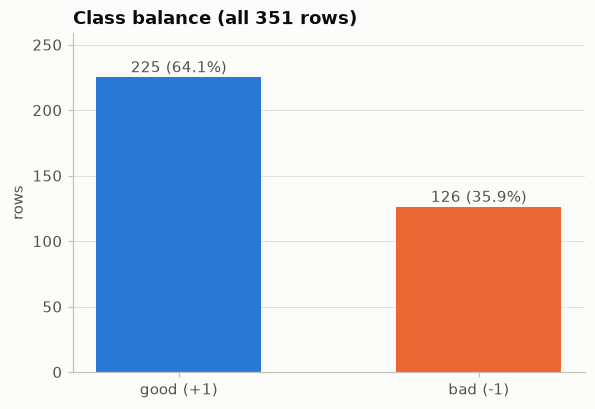

In [7]:
counts = pd.Series(y_all).value_counts().reindex([1.0, -1.0])
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([CLASS_NAME[c] for c in counts.index], counts.values, width=0.55,
              color=[CLASS_COLOR[c] for c in counts.index])
for bar, c in zip(bars, counts.index):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 4, f"{counts[c]} ({counts[c] / len(y_all):.1%})",
            ha="center", color=INK2, fontsize=10)
ax.set(ylabel="rows", title="Class balance (all 351 rows)", ylim=(0, counts.max() * 1.15))
ax.grid(axis="x", visible=False)
fig.savefig(FIG / "class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

**Class balance:** 225 good (64.1%) vs 126 bad (35.9%), about 1.8 : 1. A classifier that always says "good" already scores 64.1% accuracy, so that is the bar every model must beat, and accuracy alone can hide a model that is weak on the "bad" class.

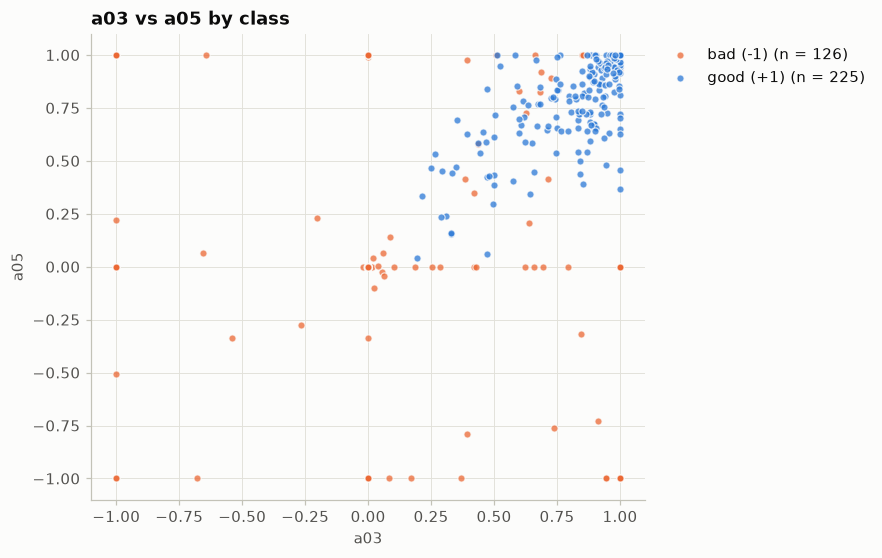

In [8]:
PAIR = ("a03", "a05")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for c in (-1.0, 1.0):
    mask = y_all == c
    ax.scatter(raw.loc[mask, PAIR[0]], raw.loc[mask, PAIR[1]], s=22, color=CLASS_COLOR[c], alpha=0.75,
               edgecolors=SURFACE, linewidths=0.8, label=f"{CLASS_NAME[c]} (n = {mask.sum()})")
ax.set(xlabel=PAIR[0], ylabel=PAIR[1], title=f"{PAIR[0]} vs {PAIR[1]} by class", xlim=(-1.1, 1.1), ylim=(-1.1, 1.1))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.savefig(FIG / "pair_a03_a05.png", dpi=150, bbox_inches="tight")
plt.show()

**a03 vs a05:** good returns sit in one tight cluster in the top-right corner (both values near +1), while bad returns are scattered over the whole square, including many at exactly 0 or ±1 and some inside the good cluster. The bad class surrounds the good one rather than lying on one side of it, which a single straight line cannot separate cleanly.

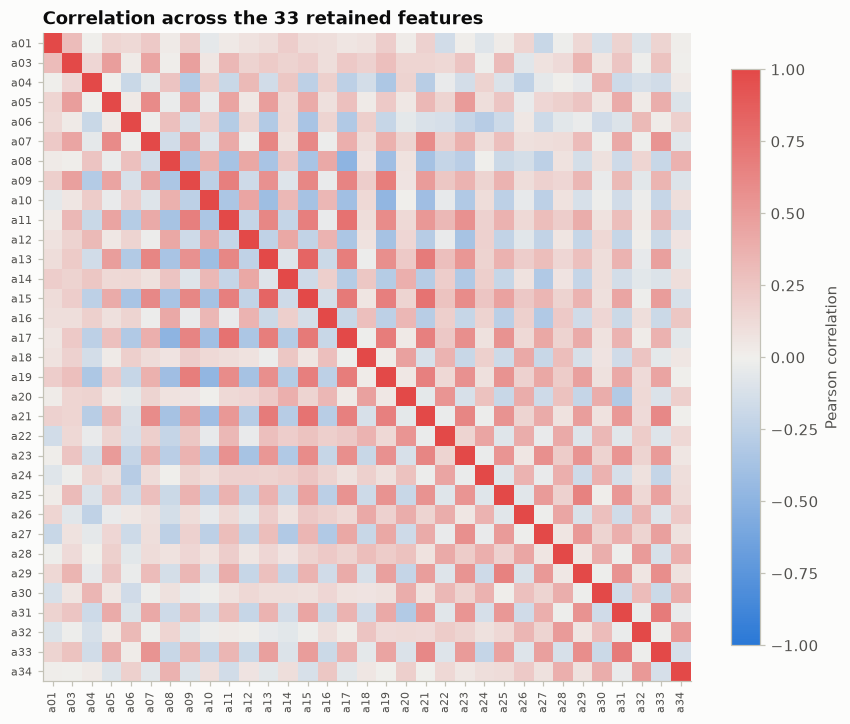

strongest correlations:
a13  a15    0.826
a11  a17    0.748
a15  a21    0.741
     a17    0.699
a31  a33    0.692
a13  a21    0.688
a17  a19    0.685
a13  a17    0.677

mean |correlation| between even-numbered (a04, a06, ...) and odd-numbered (a03, a05, ...) features: 0.150
mean |correlation| among odd-numbered features a03..a33: 0.453


In [9]:
corr = np.corrcoef(X_all, rowvar=False)
fig, ax = plt.subplots(figsize=(9.5, 8.5))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1, interpolation="nearest")
ax.grid(False)
ax.set_xticks(range(len(RETAINED)), RETAINED, rotation=90, fontsize=7)
ax.set_yticks(range(len(RETAINED)), RETAINED, fontsize=7)
ax.set_title(f"Correlation across the {len(RETAINED)} retained features")
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
fig.savefig(FIG / "feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

corr_df = pd.DataFrame(corr, index=RETAINED, columns=RETAINED)
pairs = corr_df.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("strongest correlations:")
print(pairs.sort_values(key=np.abs, ascending=False).head(8).round(3).to_string())
print(f"\nmean |correlation| between even-numbered (a04, a06, ...) and odd-numbered (a03, a05, ...) features: "
      f"{np.abs(corr_df.loc[RETAINED[2::2], RETAINED[1::2]].to_numpy()).mean():.3f}")
print(f"mean |correlation| among odd-numbered features a03..a33: "
      f"{np.abs(corr_df.loc[RETAINED[1::2], RETAINED[1::2]].to_numpy()[np.triu_indices(len(RETAINED[1::2]), 1)]).mean():.3f}")

**Correlation heatmap:** the features have clear structure. The odd-numbered columns (a03, a05, …, the first value of each pulse) are fairly strongly positively correlated with each other (mean |r| = 0.45, up to 0.83 for a13–a15), while the even-numbered columns (the second value of each pulse) are only weakly related to them (mean |r| = 0.15). Many features partly repeat the same information, grouped by which of the two values of a pulse they record.

## 2.2 Linear SVM from Scratch

### 2.2.1 Primal formulation: subgradient descent

The soft-margin linear SVM solves
$$\min_{w,\,b}\; J(w, b) = \tfrac12\lVert w\rVert^2 + C\sum_{i=1}^{n} \max\bigl(0,\; 1 - y_i(w^Tx_i + b)\bigr).$$
The hinge term is not differentiable at margin exactly 1, so a subgradient is used. With $V = \{i : y_i(w^Tx_i + b) < 1\}$ (points inside the margin or misclassified), and taking 0 as the subgradient at exactly 1:
$$g_w = w - C\sum_{i \in V} y_i x_i, \qquad g_b = -C\sum_{i \in V} y_i .$$
The per-point subgradients are **summed** (not averaged) over the batch, and the batch is the full training set: $w \leftarrow w - \eta_t g_w$, $b \leftarrow b - \eta_t g_b$, starting from $w = 0, b = 0$.

**Learning rates tried:** fixed $\eta$ = 1e-4, 1e-3, 1e-2, and the decreasing schedule $\eta_t = 10^{-2}/\sqrt{t+1}$ (the classic rate for subgradient methods, starting at the largest fixed rate). **C** is chosen from {0.01, 0.1, 1, 10, 100}. Every (C, learning rate) pair is scored by 5-fold CV accuracy, with 10,000 iterations per fit.

In [10]:
def svm_objective(w, b, X, y, C):
    return 0.5 * w @ w + C * np.maximum(0.0, 1 - y * (X @ w + b)).sum()


def primal_svm(X, y, C, lr, n_iters, snapshots=()):
    """Full-batch subgradient descent on the soft-margin primal (per-point subgradients summed).

    lr is a number or a function of the iteration t. Returns w, b, the objective before each update,
    and {iteration: (w, b)} for the requested snapshot iterations.
    """
    w, b = np.zeros(X.shape[1]), 0.0
    history, saved = np.empty(n_iters), {}
    for t in range(n_iters):
        margins = y * (X @ w + b)
        viol = margins < 1
        history[t] = 0.5 * w @ w + C * np.sum(1 - margins[viol])
        eta = lr(t) if callable(lr) else lr
        w = w - eta * (w - C * (y[viol, None] * X[viol]).sum(axis=0))
        b = b + eta * C * y[viol].sum()
        if t + 1 in snapshots:
            saved[t + 1] = (w.copy(), b)
    return w, b, history, saved


def linear_predict(model, X):
    w, b = model
    return np.where(X @ w + b >= 0, 1.0, -1.0)


PRIMAL_ITERS = 10_000
C_GRID = [0.01, 0.1, 1, 10, 100]
LEARNING_RATES = {"1e-4": 1e-4, "1e-3": 1e-3, "1e-2": 1e-2, "1e-2/sqrt(t+1)": lambda t: 1e-2 / np.sqrt(t + 1)}

start = time.time()
primal_cv = pd.DataFrame({
    name: {C: cross_val_accuracy(lambda X, y, C=C, lr=lr: primal_svm(X, y, C, lr, PRIMAL_ITERS)[:2],
                                 linear_predict, X_train, y_train, folds)[0] for C in C_GRID}
    for name, lr in LEARNING_RATES.items()}).rename_axis("C")
print(f"5-fold CV accuracy, {PRIMAL_ITERS:,} iterations per fit ({time.time() - start:.0f}s)")
primal_cv.style.format("{:.4f}").highlight_max(axis=None, props="font-weight: bold")

5-fold CV accuracy, 10,000 iterations per fit (17s)


,1e-4,1e-3,1e-2,1e-2/sqrt(t+1)
C,,,,
0.010000,0.8793,0.8722,0.8722,0.8722
0.100000,0.8757,0.8792,0.8721,0.8792
1.000000,0.8686,0.8686,0.8615,0.8722
10.000000,0.8581,0.8722,0.7653,0.8509
100.000000,0.8474,0.8545,0.8013,0.8545


In [11]:
rows = {}
for C in C_GRID:
    for name, lr in LEARNING_RATES.items():
        _, _, hist, _ = primal_svm(X_train, y_train, C, lr, PRIMAL_ITERS)
        tail = hist[-1000:]
        rows[(C, name)] = {"objective @100": hist[99], "objective @1,000": hist[999], "objective @10,000": hist[-1],
                           "lowest objective": hist.min(),
                           "last-1,000 swing / lowest": np.ptp(tail) / hist.min()}
primal_convergence = pd.DataFrame(rows).T.rename_axis(["C", "learning rate"])
primal_convergence.style.format({c: "{:.4g}" for c in primal_convergence.columns})

**What I observe with each learning rate** (the "swing" column is how much the objective moves over the last 1,000 iterations, relative to its lowest value; large means it is bouncing, not settling):

- **1e-4: stable but too slow.** At C = 0.1 the objective is still 7.223 after 10,000 iterations, while the optimum is 7.1865 (found by the QP in 2.2.2). Its top CV score at C = 0.01 (0.8793) comes from weights that have not finished growing from 0, which acts like extra regularization, not from a better optimum.
- **1e-3: good at small C, unstable at large C.** At C = 0.1 it reaches the lowest objective of all (7.187, within 0.01% of the optimum) and barely swings (0.04%). At C = 10 it swings by 98% of the objective, and at C = 100 by 32 times.
- **1e-2: too large.** With summed subgradients the step is $\eta\,C\sum_{i \in V} y_i x_i$, so it grows with both C and the number of margin violators. Even at C = 0.1 it stalls above the optimum (7.208) and swings 0.5%. At C = 1 it swings 8×, at C = 10 48×, and CV accuracy collapses to 0.77.
- **Schedule $10^{-2}/\sqrt{t+1}$: fast start, stable everywhere, slow finish.** It starts as fast as 1e-2, but the shrinking steps stop the oscillation at every C (swing ≤ 0.4 even at C = 100, against 201 for 1e-2). The price is a slow finish: at C = 0.1 it ends at 7.191, slightly behind 1e-3.

**CV accuracy barely depends on the learning rate once the optimizer converges.** The best scores (0.8793 and 0.8792) differ by far less than one validation point (1/56 ≈ 0.018). Larger C lowers CV accuracy to about 0.85, meaning less regularization overfits.

**Choice.**
- **C = 0.1:** it has the best CV accuracy among runs that actually converged (0.8792), and the exact QP solution in 2.2.2 confirms it is the best C.
- **Fixed learning rate 1e-3:** at C = 0.1 it ties the schedule on CV accuracy (0.8792) but gets much closer to the true optimum (weights within about 1e-3 of the QP solution after 10,000 iterations, see 2.2.2). The decreasing schedule would be the safer default if C were larger, where 1e-3 starts to oscillate.

**Hyperparameters used:** C = 0.1, fixed learning rate η = 1e-3, 10,000 iterations, full batch (all 281 training rows, per-point subgradients summed), starting from w = 0, b = 0.

In [12]:
C_LINEAR = 0.1
CHOSEN_LR = "1e-3"
print(f"settled on C = {C_LINEAR}, learning rate = {CHOSEN_LR}, {PRIMAL_ITERS:,} iterations "
      f"(CV accuracy {primal_cv.loc[C_LINEAR, CHOSEN_LR]:.4f})")

settled on C = 0.1, learning rate = 1e-3, 10,000 iterations (CV accuracy 0.8792)


### 2.2.2 Dual formulation: quadratic program

**Derivation.** Write the primal with slack variables $\xi_i$:
$$\min_{w,b,\xi}\ \tfrac12\lVert w\rVert^2 + C\sum_i \xi_i \quad\text{s.t.}\quad y_i(w^Tx_i + b) \ge 1 - \xi_i,\ \ \xi_i \ge 0 .$$
With multipliers $\alpha_i \ge 0$ for the margin constraints and $\mu_i \ge 0$ for $\xi_i \ge 0$, the Lagrangian is
$$\mathcal{L} = \tfrac12\lVert w\rVert^2 + C\sum_i \xi_i - \sum_i \alpha_i\bigl[y_i(w^Tx_i + b) - 1 + \xi_i\bigr] - \sum_i \mu_i \xi_i .$$
Setting its derivatives to zero:
- $\partial\mathcal{L}/\partial w = 0 \Rightarrow w = \sum_i \alpha_i y_i x_i$
- $\partial\mathcal{L}/\partial b = 0 \Rightarrow \sum_i \alpha_i y_i = 0$
- $\partial\mathcal{L}/\partial \xi_i = 0 \Rightarrow C - \alpha_i - \mu_i = 0$, and with $\mu_i \ge 0$ this gives $0 \le \alpha_i \le C$.

Substituting back eliminates $w, b, \xi$ and gives the **dual**:
$$\max_{\alpha}\ \sum_i \alpha_i - \tfrac12\sum_{i,j}\alpha_i\alpha_j y_i y_j\, x_i^Tx_j \quad\text{s.t.}\quad 0 \le \alpha_i \le C,\ \ \sum_i \alpha_i y_i = 0 .$$

**Standard QP form.** `cvxopt.solvers.qp` solves $\min_x \tfrac12 x^TPx + q^Tx$ s.t. $Gx \le h$, $Ax = b$. Negating the dual objective turns the maximization into a minimization:

| Solver input | Value | Meaning in the derivation |
|---|---|---|
| $x$ | $\alpha \in \mathbb{R}^n$ | the Lagrange multipliers, one per training point |
| $P$ | $P_{ij} = y_i y_j\, x_i^Tx_j$ ($n \times n$) | quadratic term of the negated dual; $x_i^Tx_j$ is replaced by $K(x_i, x_j)$ for kernels |
| $q$ | $-\mathbf{1}$ ($n$) | the linear term $-\sum_i \alpha_i$ of the negated dual |
| $G$ | $\begin{bmatrix}-I\\ I\end{bmatrix}$ ($2n \times n$) | stacks $-\alpha_i \le 0$ and $\alpha_i \le C$ |
| $h$ | $\begin{bmatrix}\mathbf{0}\\ C\mathbf{1}\end{bmatrix}$ ($2n$) | the right-hand sides $0$ and $C$ of the box constraint |
| $A$ | $y^T$ ($1 \times n$) | the equality constraint $\sum_i \alpha_i y_i$ … |
| $b$ | $0$ | … $= 0$ (from $\partial\mathcal{L}/\partial b = 0$) |

**Extracting the model.**
- **Support vectors:** $\alpha_i > 10^{-5}$.
- **Bias:** from the KKT conditions, a point with $0 < \alpha_i < C$ lies exactly on the margin, $y_i f(x_i) = 1$, so $b = y_i - \sum_j \alpha_j y_j K(x_j, x_i)$. I average this over all such margin support vectors ($10^{-5} < \alpha_i < C - 10^{-5}$) for numerical stability.
- **Decision function:** $f(x) = \sum_{i \in SV} \alpha_i y_i K(x_i, x) + b$.
- **Linear kernel only:** $w = \sum_i \alpha_i y_i x_i$.

In [13]:
def linear_kernel(A, B):
    return A @ B.T


def fit_dual_svm(X, y, C, kernel=linear_kernel):
    n = len(y)
    K = kernel(X, X)
    P = matrix(np.outer(y, y) * K)
    q = matrix(-np.ones(n))
    G = matrix(np.vstack([-np.eye(n), np.eye(n)]))
    h = matrix(np.concatenate([np.zeros(n), np.full(n, float(C))]))
    A = matrix(y.reshape(1, -1))
    b = matrix(0.0)
    sol = solvers.qp(P, q, G, h, A, b)
    alpha = np.ravel(sol["x"])
    sv = alpha > SV_THRESHOLD
    on_margin = sv & (alpha < C - SV_THRESHOLD)
    f_without_b = K[:, sv] @ (alpha[sv] * y[sv])
    use = on_margin if on_margin.any() else sv
    bias = float(np.mean(y[use] - f_without_b[use]))
    return {"alpha": alpha, "sv": sv, "on_margin": on_margin, "X_sv": X[sv], "y_sv": y[sv], "alpha_sv": alpha[sv],
            "b": bias, "kernel": kernel, "C": C, "status": sol["status"],
            "dual_objective": float(alpha.sum() - 0.5 * (alpha * y) @ K @ (alpha * y))}


def dual_decision(model, X):
    return model["kernel"](X, model["X_sv"]) @ (model["alpha_sv"] * model["y_sv"]) + model["b"]


def dual_predict(model, X):
    return np.where(dual_decision(model, X) >= 0, 1.0, -1.0)


def linear_weights(model):
    return (model["alpha_sv"] * model["y_sv"]) @ model["X_sv"]

In [14]:
dual_linear = fit_dual_svm(X_train, y_train, C_LINEAR)
n_sv, n_margin = int(dual_linear["sv"].sum()), int(dual_linear["on_margin"].sum())
w_dual, b_dual = linear_weights(dual_linear), dual_linear["b"]

print(f"solver status: {dual_linear['status']}, C = {C_LINEAR}")
print(f"support vectors (alpha > {SV_THRESHOLD:g}): {n_sv} of {len(y_train)} = {n_sv / len(y_train):.1%} of the training set")
print(f"  on the margin (0 < alpha < C): {n_margin}, at the bound (alpha = C): {n_sv - n_margin}")
print(f"bias b = {b_dual:.4f}")
print(f"dual objective = {dual_linear['dual_objective']:.4f}, primal objective of (w, b) recovered from alpha = "
      f"{svm_objective(w_dual, b_dual, X_train, y_train, C_LINEAR):.4f}")
print(f"training accuracy = {accuracy(y_train, dual_predict(dual_linear, X_train)):.4f}")
cv_dual_linear = cross_val_accuracy(lambda X, y: fit_dual_svm(X, y, C_LINEAR), dual_predict, X_train, y_train, folds)[0]
print(f"5-fold CV accuracy (dual, linear kernel) = {cv_dual_linear:.4f}")

solver status: optimal, C = 0.1
support vectors (alpha > 1e-05): 96 of 281 = 34.2% of the training set
  on the margin (0 < alpha < C): 20, at the bound (alpha = C): 76
bias b = 0.2836
dual objective = 7.1865, primal objective of (w, b) recovered from alpha = 7.1865
training accuracy = 0.9146
5-fold CV accuracy (dual, linear kernel) = 0.8792


In [15]:
dual_cv_by_C = pd.DataFrame({"5-fold CV accuracy (exact QP solution)": {
    C: cross_val_accuracy(lambda X, y, C=C: fit_dual_svm(X, y, C), dual_predict, X_train, y_train, folds)[0] for C in C_GRID}}).T
dual_cv_by_C.style.format("{:.4f}")

,0.010000,0.100000,1.000000,10.000000,100.000000
5-fold CV accuracy (exact QP solution),0.8722,0.8792,0.8722,0.8509,0.8439


**Solution at C = 0.1** (solver status: optimal)
- **Support vectors:** 96 of 281 training points have α > 1e-5, i.e. **34.2% of the training set**. 20 of them lie exactly on the margin (0 < α < C), and 76 are at the upper bound α = C (inside the margin or misclassified).
- **Bias:** b = 0.2836, averaged over the 20 margin support vectors.
- **Correctness check:** the dual objective (7.1865) equals the primal objective of the (w, b) recovered from α (7.1865). The duality gap is zero, so the QP is solved and w and b are extracted correctly.
- **Accuracy:** training accuracy 0.9146. 5-fold CV accuracy with the exact QP solution is 0.8792, the same as subgradient descent at the chosen settings.

**Choice of C confirmed:** refitting the exact QP for every C gives CV accuracy 0.8722, **0.8792**, 0.8722, 0.8509 and 0.8439 for C = 0.01, 0.1, 1, 10 and 100. C = 0.1 is best without any optimizer noise.

**Explicit weight vector (linear kernel only):** $w = \sum_i \alpha_i y_i x_i$ over the support vectors (`linear_weights`). It is compared with the subgradient-descent weights below.

In [16]:
CHECKPOINTS = (100, 1_000, 10_000)
compare_lrs = {"fixed 1e-3": 1e-3, "schedule 1e-2/sqrt(t+1)": LEARNING_RATES["1e-2/sqrt(t+1)"]}
rows = {}
for name, lr in compare_lrs.items():
    _, _, _, snaps = primal_svm(X_train, y_train, C_LINEAR, lr, max(CHECKPOINTS), snapshots=CHECKPOINTS)
    for it in CHECKPOINTS:
        w_p, b_p = snaps[it]
        rows[(name, it)] = {"max |w_primal - w_dual|": np.abs(w_p - w_dual).max(), "|b_primal - b_dual|": abs(b_p - b_dual),
                            "primal objective": svm_objective(w_p, b_p, X_train, y_train, C_LINEAR)}
weight_gap = pd.DataFrame(rows).T.rename_axis(["learning rate", "iterations"])
print(f"QP optimum (dual objective) = {dual_linear['dual_objective']:.4f}; largest |w_dual| = {np.abs(w_dual).max():.4f}")
weight_gap.style.format("{:.4g}")

QP optimum (dual objective) = 7.1865; largest |w_dual| = 0.6156


**Largest elementwise difference between the subgradient-descent weights and the QP weights** (the largest QP weight is 0.616 in absolute value):

| Iterations | Fixed η = 1e-3 | Schedule 1e-2/√(t+1) |
|---|---|---|
| 100 | 0.356 | 0.288 |
| 1,000 | 0.096 | 0.158 |
| 10,000 | **0.0011** | 0.033 |

- **Fixed 1e-3:** the gap shrinks quickly and keeps shrinking: from 0.356 to 0.096 (3.7× smaller) over the first 900 iterations, then about 87× smaller over the next 9,000, ending at 0.2% of the largest weight. The bias follows (0.076 → 0.0012). A fixed step can only get within a distance that shrinks with η of a non-smooth optimum. The objective plot in 2.2.3 shows this run reaching such a floor (bouncing in a narrow band after about 2,000 iterations), so running much longer would help little. At η = 1e-3 that floor is small enough that the weights match the QP solution to within 0.2%.
- **Schedule:** it is ahead at 100 iterations (0.288, because its early steps are 10× larger) but falls behind afterwards. The steps shrink like $1/\sqrt{t}$, so the error also falls slowly (0.288 → 0.158 → 0.033, roughly 2–5× per 10× more iterations). It never oscillates and is still improving steadily, but it needs many more iterations to match the accuracy of the fixed rate.

Both runs are clearly converging to the QP weights, which confirms that the primal and dual implementations solve the same problem.

### 2.2.3 Convergence and comparison

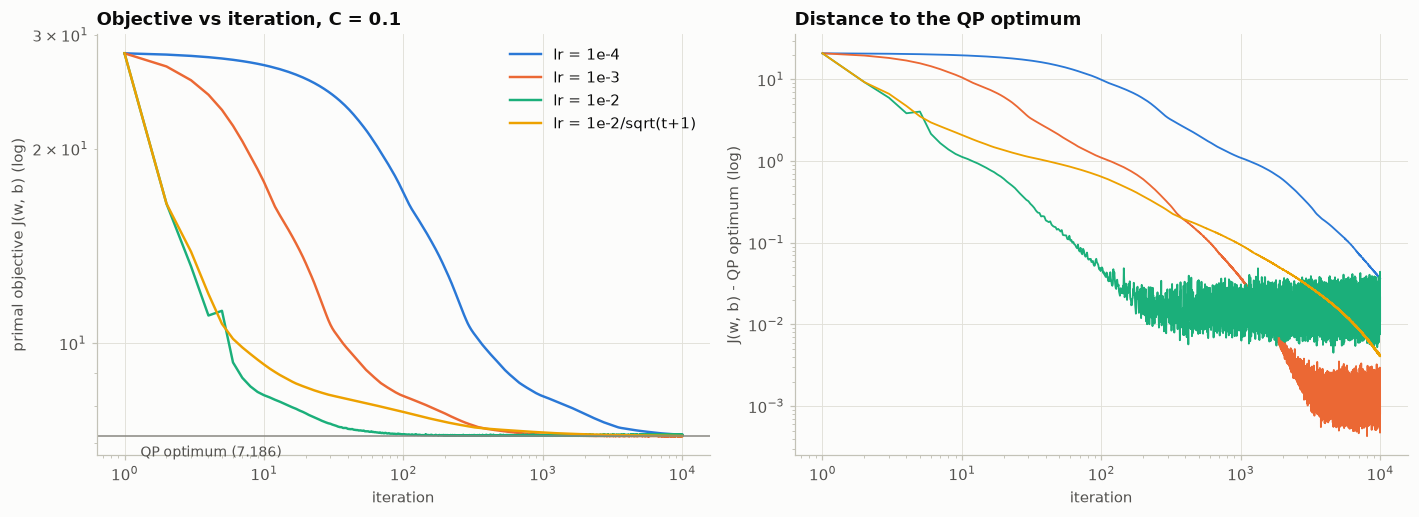

,J @100,"J @1,000","J @10,000","gap @10,000","largest rise between consecutive iterations (last 1,000)"
1e-4,17.11,8.285,7.223,0.03619,0.0001381
1e-3,8.29,7.223,7.187,0.0008152,0.001837
1e-2,7.234,7.197,7.208,0.02133,0.02174
1e-2/sqrt(t+1),7.832,7.281,7.191,0.004094,0.0001952


In [17]:
curves = {name: primal_svm(X_train, y_train, C_LINEAR, lr, PRIMAL_ITERS)[2] for name, lr in LEARNING_RATES.items()}
J_star = dual_linear["dual_objective"]
iters = np.arange(1, PRIMAL_ITERS + 1)
fig, (ax, ax_gap) = plt.subplots(1, 2, figsize=(13, 4.8))
for name, hist in curves.items():
    ax.plot(iters, hist, label=f"lr = {name}", linewidth=1.6)
    ax_gap.plot(iters, np.maximum(hist - J_star, 1e-12), label=f"lr = {name}", linewidth=1.2)
ax.axhline(J_star, color=MUTED, linewidth=1)
ax.text(1.3, J_star * 0.93, f"QP optimum ({J_star:.3f})", color=INK2, fontsize=9)
ax.set(xscale="log", yscale="log", xlabel="iteration", ylabel="primal objective J(w, b) (log)",
       title=f"Objective vs iteration, C = {C_LINEAR}")
ax.legend(loc="upper right")
ax_gap.set(xscale="log", yscale="log", xlabel="iteration", ylabel="J(w, b) - QP optimum (log)",
           title="Distance to the QP optimum")
fig.tight_layout()
fig.savefig(FIG / "primal_objective.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({name: {"J @100": h[99], "J @1,000": h[999], "J @10,000": h[-1],
                     "gap @10,000": h[-1] - J_star, "largest rise between consecutive iterations (last 1,000)": np.diff(h[-1000:]).max()}
              for name, h in curves.items()}).T.style.format("{:.4g}")

**Convergence behaviour** (C = 0.1, all four runs over the same 10,000 iterations):
- **Common start:** every run starts at J = C·n = 0.1 × 281 = 28.1, because with w = 0 every point has hinge loss 1.
- **Speed scales with step size:** 1e-2 and the schedule drop fastest (below 8 within 100 iterations), 1e-3 gets there by about 1,000, and 1e-4 is about 10× slower again. On log axes, each 10× smaller fixed rate shifts the curve about one decade to the right.
- **The right panel shows how close each gets to the optimum:**
  - **1e-2:** stops improving after about 200 iterations and then bounces in a band around a gap of 0.01 (the objective still rises by up to 0.022 in a single step near the end). Subgradient descent is not a true descent method: a fixed step circles the kink of the hinge loss instead of settling on it.
  - **1e-3:** does the same, but about 10× lower. It reaches the smallest gap, then from about 2,000 iterations bounces in a band around 1e-3 (0.0008 at iteration 10,000). With a fixed step the objective can only get within a distance that shrinks with η. That is why the 1e-2 band sits about 10× above the 1e-3 band.
  - **Schedule:** the only run with no floor. Its steps keep shrinking, so it falls smoothly (bumps ≤ 2e-4) and is still going down at 10,000 iterations (gap 0.0041). Given more iterations it would pass the fixed 1e-3 run.
  - **1e-4:** smooth but slow, still 0.036 away after 10,000 iterations.

In [18]:
def best_time(fn, repeats=5):
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        fn()
        times.append(time.perf_counter() - start)
    return min(times)

t_primal = best_time(lambda: primal_svm(X_train, y_train, C_LINEAR, LEARNING_RATES[CHOSEN_LR], PRIMAL_ITERS), repeats=3)
t_qp = best_time(lambda: fit_dual_svm(X_train, y_train, C_LINEAR))
print(f"training on {len(y_train)} rows x {X_train.shape[1]} features, C = {C_LINEAR} (best of several runs)")
print(f"  subgradient descent, {PRIMAL_ITERS:,} iterations, lr = {CHOSEN_LR}: {t_primal:.3f} s")
print(f"  dual QP (cvxopt):                                        {t_qp:.3f} s")

training on 281 rows x 33 features, C = 0.1 (best of several runs)
  subgradient descent, 10,000 iterations, lr = 1e-3: 0.175 s
  dual QP (cvxopt):                                        0.040 s


**Training time** on the full training set (281 rows × 33 features, C = 0.1, best of several runs): subgradient descent for 10,000 iterations takes about **0.19 s**, and the cvxopt QP about **0.06 s**. The exact value varies slightly between runs.

At this size the QP is faster, but it is the approach that scales worse. **I expect subgradient descent (the primal) to scale much better with the number of training examples n:**
- **Subgradient descent:** each iteration costs $O(nd)$ time and needs only the $n \times d$ data, so the cost grows linearly with n. It can also use mini-batches, making each step independent of n.
- **QP:** needs the dense $n \times n$ matrix $P$ (and here a dense $2n \times n$ matrix $G$). That costs $O(n^2 d)$ time to build and $O(n^2)$ memory, and each interior-point iteration solves an $n \times n$ linear system, which costs $O(n^3)$.

For n = 281 this is trivial. For n = 100,000, $P$ alone would take 80 GB of memory.

## 2.3 Kernels

The kernels replace the dot product $x_i^Tx_j$ in the dual (the matrix $P_{ij} = y_iy_jK(x_i, x_j)$) and in the decision function $f(x) = \sum_{i \in SV}\alpha_i y_i K(x_i, x) + b$. `fit_dual_svm` from 2.2.2 already takes the kernel as an argument, so nothing else changes.

**How hyperparameters are chosen here.** Every setting is picked by 5-fold CV accuracy on the training set. The degree (or γ) and C are searched **jointly** over a grid with C ∈ {0.01, 0.1, 1, 10, 100}. The best (degree or γ, C) pair wins; ties go to the smaller degree or γ, then the smaller C. The full CV grid is shown for transparency. The curves and boundary plots then hold C fixed at the selected value, so only the degree or γ changes between points and panels.

In [19]:
def poly_kernel(degree, gamma, coef0=1.0):
    def k(A, B):
        return (gamma * (A @ B.T) + coef0) ** degree
    return k


def rbf_kernel(gamma):
    def k(A, B):
        sq_dist = np.sum(A ** 2, axis=1)[:, None] + np.sum(B ** 2, axis=1)[None, :] - 2 * A @ B.T
        return np.exp(-gamma * np.maximum(sq_dist, 0.0))
    return k


C_GRID_KERNEL = [0.01, 0.1, 1, 10, 100]


def cv_grid(X, y, kernels, Cs=C_GRID_KERNEL):
    """5-fold CV accuracy for every (kernel setting, C); rows = kernel settings, columns = C."""
    return pd.DataFrame({C: {name: cross_val_accuracy(lambda Xf, yf, C=C, k=k: fit_dual_svm(Xf, yf, C, k),
                                                      dual_predict, X, y, folds)[0]
                             for name, k in kernels.items()} for C in Cs})


def best_setting(grid):
    """(kernel setting, C) with the highest CV accuracy; ties go to the earlier setting, then the smaller C."""
    return grid.stack().idxmax()


def fixed_C_curve(X, y, kernels, grid, C):
    """CV accuracy (from the grid), training accuracy and support vectors of each kernel setting at one fixed C."""
    rows = {}
    for name, k in kernels.items():
        model = fit_dual_svm(X, y, C, k)
        rows[name] = {"CV accuracy": grid.loc[name, C], "train accuracy": accuracy(y, dual_predict(model, X)),
                      "support vectors": int(model["sv"].sum())}
    return pd.DataFrame(rows).T


def plot_boundary(ax, model, X2, y, title):
    lo, hi = X2.min(axis=0) - 0.4, X2.max(axis=0) + 0.4
    g0, g1 = np.meshgrid(np.linspace(lo[0], hi[0], 300), np.linspace(lo[1], hi[1], 300))
    F = dual_decision(model, np.column_stack([g0.ravel(), g1.ravel()])).reshape(g0.shape)
    ax.contourf(g0, g1, F, levels=[-np.inf, 0, np.inf], colors=["#fbe3d7", "#dbe8f9"])
    if F.min() < 0 < F.max():
        ax.contour(g0, g1, F, levels=[0], colors=INK, linewidths=1.2)
    for c in (-1.0, 1.0):
        m = y == c
        ax.scatter(X2[m, 0], X2[m, 1], s=12, color=CLASS_COLOR[c], edgecolors=SURFACE, linewidths=0.5,
                   label=CLASS_NAME[c])
    ax.set(title=title, xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]))
    ax.grid(False)

### 2.3.1 A case where linear fails

**Baseline:** a classifier that always predicts the majority class of its fitting folds ("good"). Its 5-fold CV accuracy is the bar a useful model has to beat.

**Search:** instead of guessing, the linear-kernel QP from 2.2.2 is fit on **every one of the 528 pairs** of retained features (C = 1, 5-fold CV).

In [20]:
def fit_majority(X, y):
    return 1.0 if np.mean(y == 1) >= 0.5 else -1.0


def predict_majority(label, X):
    return np.full(len(X), label)


majority_cv = cross_val_accuracy(fit_majority, predict_majority, X_train, y_train, folds)[0]
print(f"majority-class baseline, 5-fold CV accuracy: {majority_cv:.4f}")

start = time.time()
pair_rows = []
for i in range(len(RETAINED)):
    for j in range(i + 1, len(RETAINED)):
        acc = cross_val_accuracy(lambda X, y: fit_dual_svm(X, y, 1.0), dual_predict, X_train[:, [i, j]], y_train, folds)[0]
        pair_rows.append({"pair": f"{RETAINED[i]} & {RETAINED[j]}", "linear CV accuracy (C = 1)": acc})
pair_search = pd.DataFrame(pair_rows).sort_values("linear CV accuracy (C = 1)").reset_index(drop=True)
n_fail = int((pair_search["linear CV accuracy (C = 1)"] <= majority_cv + 1e-12).sum())
print(f"{len(pair_search)} pairs searched in {time.time() - start:.0f}s; {n_fail} do not beat the baseline")
pair_search.head(10).style.format({"linear CV accuracy (C = 1)": "{:.4f}"})

majority-class baseline, 5-fold CV accuracy: 0.6406


528 pairs searched in 45s; 234 do not beat the baseline


,pair,linear CV accuracy (C = 1)
0,a15 & a25,0.5835
1,a13 & a25,0.5906
2,a24 & a25,0.6049
3,a15 & a21,0.6049
4,a09 & a21,0.6084
5,a13 & a21,0.6085
6,a21 & a25,0.6085
7,a11 & a25,0.6120
8,a25 & a33,0.6120
9,a25 & a34,0.6120


Many pairs fail. To pick one where the failure is about the **shape** of the classes rather than the pair simply being uninformative, I re-check the 40 weakest pairs with C tuned over the full grid, and compare with an RBF kernel (γ = 1, C ∈ {1, 10}).

In [21]:
start = time.time()
check_rows = []
for pair in pair_search["pair"].head(40):
    f_a, f_b = pair.split(" & ")
    Xp = X_train[:, [RETAINED.index(f_a), RETAINED.index(f_b)]]
    lin = max(cross_val_accuracy(lambda X, y, C=C: fit_dual_svm(X, y, C), dual_predict, Xp, y_train, folds)[0]
              for C in C_GRID_KERNEL)
    rbf = max(cross_val_accuracy(lambda X, y, C=C: fit_dual_svm(X, y, C, rbf_kernel(1.0)), dual_predict, Xp, y_train, folds)[0]
              for C in (1, 10))
    check_rows.append({"pair": pair, "linear, best C": lin, "RBF (gamma = 1), best C": rbf, "gain": rbf - lin})
pair_check = pd.DataFrame(check_rows).sort_values("gain", ascending=False).reset_index(drop=True)
print(f"checked in {time.time() - start:.0f}s")
pair_check.head(10).style.format({c: "{:.4f}" for c in pair_check.columns if c != "pair"})

checked in 26s


,pair,"linear, best C","RBF (gamma = 1), best C",gain
0,a21 & a28,0.6406,0.8752,0.2346
1,a21 & a22,0.6406,0.8683,0.2277
2,a13 & a24,0.6406,0.8646,0.2240
3,a13 & a28,0.6406,0.8612,0.2206
4,a21 & a32,0.6406,0.8612,0.2206
5,a15 & a25,0.6406,0.8577,0.2171
6,a15 & a28,0.6406,0.8504,0.2098
7,a13 & a25,0.6406,0.8469,0.2063
8,a15 & a16,0.6692,0.8755,0.2063
9,a15 & a34,0.6406,0.8469,0.2063


pair a21 & a28: linear-kernel 5-fold CV accuracy by C:


,0.010000,0.100000,1.000000,10.000000,100.000000
linear,0.6406,0.6370,0.6192,0.6192,0.6156


best: 0.6406 at C = 0.01 (majority baseline 0.6406)
at that C the model predicts 'good' for 100% of training rows; w = [0. 0.], b = 1.000


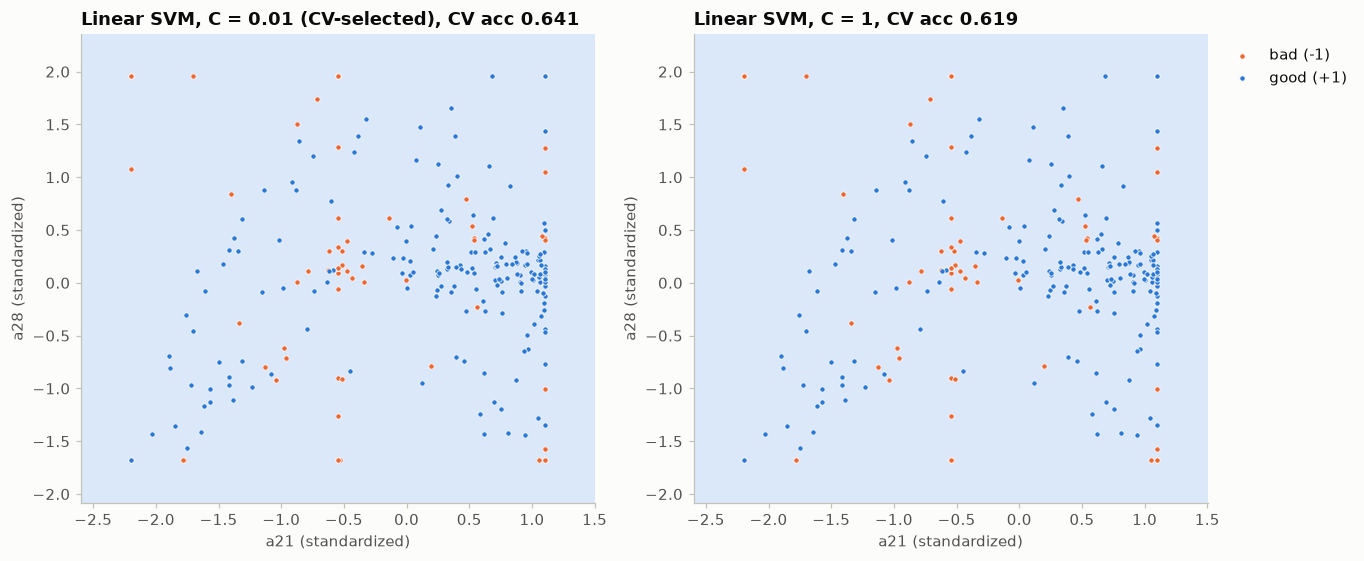

In [22]:
PAIR_23 = ("a21", "a28")
pair_idx = [RETAINED.index(f) for f in PAIR_23]
X_pair = X_train[:, pair_idx]

lin_pair_grid = cv_grid(X_pair, y_train, {"linear": linear_kernel})
C_lin_pair = lin_pair_grid.loc["linear"].idxmax()
lin_pair_model = fit_dual_svm(X_pair, y_train, C_lin_pair)
print(f"pair {PAIR_23[0]} & {PAIR_23[1]}: linear-kernel 5-fold CV accuracy by C:")
display(lin_pair_grid.style.format("{:.4f}"))
print(f"best: {lin_pair_grid.loc['linear', C_lin_pair]:.4f} at C = {C_lin_pair:g} (majority baseline {majority_cv:.4f})")
lin_train_pred = dual_predict(lin_pair_model, X_pair)
print(f"at that C the model predicts 'good' for {np.mean(lin_train_pred == 1):.0%} of training rows; "
      f"w = {np.round(linear_weights(lin_pair_model), 4)}, b = {lin_pair_model['b']:.3f}")

lin_c1 = fit_dual_svm(X_pair, y_train, 1.0)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
plot_boundary(axes[0], lin_pair_model, X_pair, y_train,
              f"Linear SVM, C = {C_lin_pair:g} (CV-selected), CV acc {lin_pair_grid.loc['linear', C_lin_pair]:.3f}")
plot_boundary(axes[1], lin_c1, X_pair, y_train,
              f"Linear SVM, C = 1, CV acc {lin_pair_grid.loc['linear', 1]:.3f}")
for ax in axes:
    ax.set(xlabel=f"{PAIR_23[0]} (standardized)", ylabel=f"{PAIR_23[1]} (standardized)")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
fig.savefig(FIG / "pair_linear_boundary.png", dpi=150, bbox_inches="tight")
plt.show()

**The pair: a21 & a28.** 234 of the 528 pairs do not beat the majority baseline at C = 1. Among the weakest 40, a21 & a28 fails at **every** C and shows the largest gain once a nonlinear kernel is allowed, so the failure is about shape rather than an uninformative pair.

- **Linear SVM, 5-fold CV accuracy: 0.6406 at best** (C = 0.01), exactly the majority baseline of 0.6406. At that C the solver returns w = 0 and b = 1: it gives up and predicts "good" for every point. Larger C values do worse: 0.637 at C = 0.1, and 0.619–0.616 for C ≥ 1.
- **Plot:** in both panels the whole plotted region is on the "good" side, so there is no boundary line inside the data range.

**Why a line cannot do better: the shape of the classes.**
- The **bad** points are in two separate places: a small cluster in the **middle** of the plot (around a21 ≈ −0.5, a28 ≈ 0 to 0.5), and a scattered **outer ring** at the edges (a28 near ±1.5–2, a21 at its extremes).
- The **good** points fill the band **between** them.

A linear boundary splits the plane into two half-planes, so it can cut off either part of the outer ring or the middle cluster, never both. Any such cut also removes many good points, since the good band surrounds the middle cluster and lies inside the ring. Every line loses about as many good points as it gains bad ones, so the best linear rule is to predict the majority class everywhere.

**Kernels do substantially better on the same pair** (details in 2.3.2 and 2.3.3):
- **RBF (γ = 1, C = 100): CV accuracy 0.8788**
- **Polynomial (degree 5, C = 10): CV accuracy 0.8788**

That is about **+24 percentage points** over the linear SVM, because both kernels can draw closed, curved boundaries: a pocket around the middle cluster and a fence against the outer ring.

### 2.3.2 Polynomial kernel

$$K(x, x') = (\gamma\, x^Tx' + c_0)^d, \qquad c_0 = 1 .$$
**γ = 1 / (number of retained features the model is fit on):** γ = 1/33 ≈ 0.0303 on the full Ionosphere data, and γ = 1/2 on the two-feature pair (where only 2 features are retained). **coef0 = 1** throughout. The degree is swept from 1 to 5.

gamma (all 33 features) = 0.0303, gamma (pair) = 0.5, coef0 = 1.0


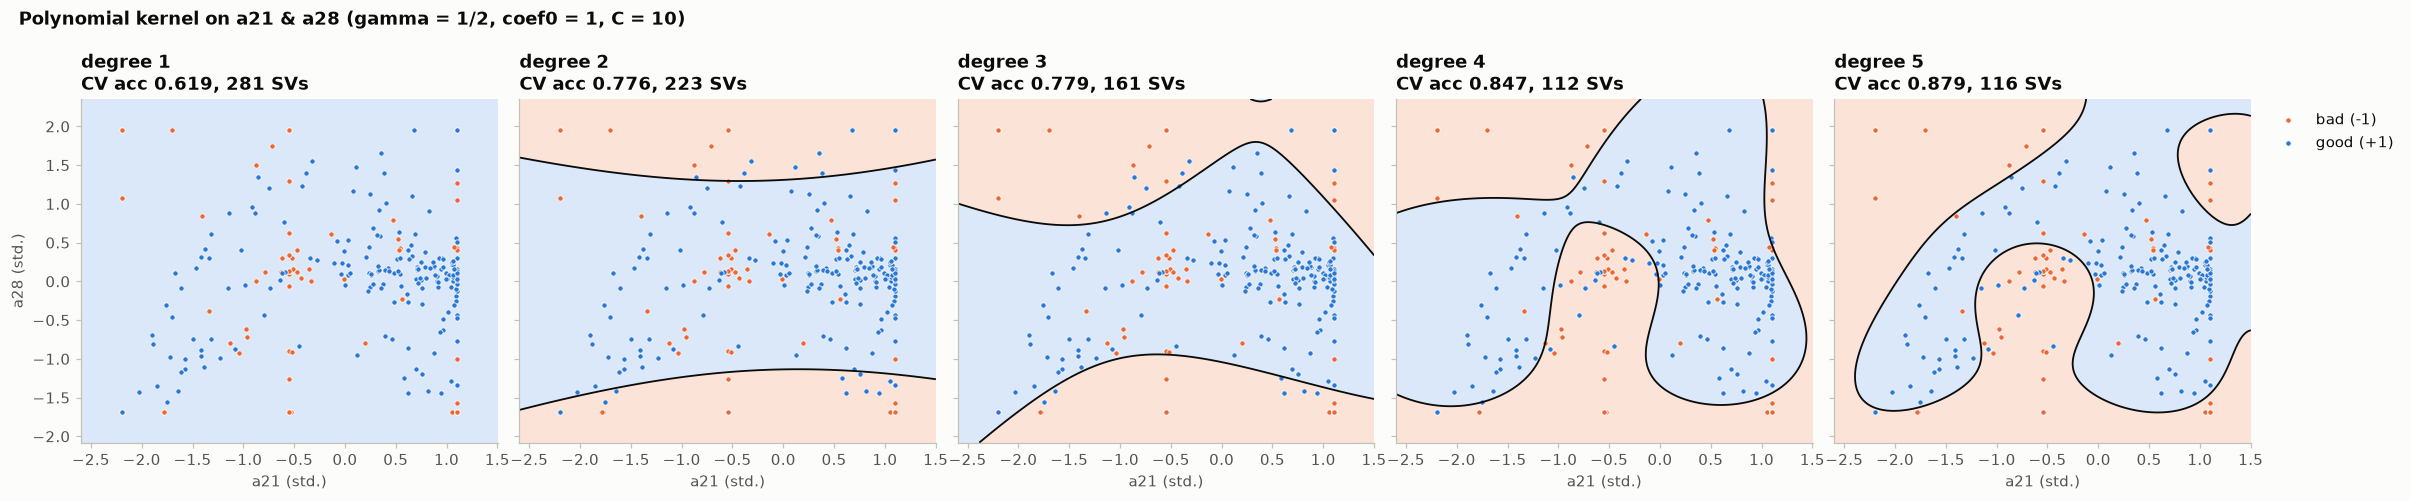

pair sweep: 6s; best on the pair: degree 5, C = 10 (CV accuracy 0.8788); all panels use C = 10


,0.010000,0.100000,1.000000,10.000000,100.000000
degree,,,,,
1,0.6406,0.6406,0.6192,0.6192,0.6192
2,0.6833,0.7791,0.7756,0.7756,0.7756
3,0.7721,0.7791,0.7826,0.7790,0.7790
4,0.7969,0.8254,0.8289,0.8468,0.8574
5,0.8148,0.8289,0.8647,0.8788,0.8752


,CV accuracy,train accuracy,support vectors
1,0.6192,0.6406,281
2,0.7756,0.7758,223
3,0.7790,0.7936,161
4,0.8468,0.8790,112
5,0.8788,0.8897,116


In [23]:
GAMMA_POLY_FULL, GAMMA_POLY_PAIR, COEF0 = 1 / len(RETAINED), 1 / 2, 1.0
DEGREES = [1, 2, 3, 4, 5]
print(f"gamma (all {len(RETAINED)} features) = {GAMMA_POLY_FULL:.4f}, gamma (pair) = {GAMMA_POLY_PAIR}, coef0 = {COEF0}")

start = time.time()
poly_kernels_pair = {d: poly_kernel(d, GAMMA_POLY_PAIR, COEF0) for d in DEGREES}
poly_pair_grid = cv_grid(X_pair, y_train, poly_kernels_pair)
d_pair, C_poly_pair = best_setting(poly_pair_grid)
poly_pair_curve = fixed_C_curve(X_pair, y_train, poly_kernels_pair, poly_pair_grid, C_poly_pair)

fig, axes = plt.subplots(1, 5, figsize=(22, 4.6), sharey=True)
for ax, d in zip(axes, DEGREES):
    plot_boundary(ax, fit_dual_svm(X_pair, y_train, C_poly_pair, poly_kernels_pair[d]), X_pair, y_train,
                  f"degree {d}\nCV acc {poly_pair_curve.loc[d, 'CV accuracy']:.3f}, "
                  f"{poly_pair_curve.loc[d, 'support vectors']:.0f} SVs")
    ax.set(xlabel=f"{PAIR_23[0]} (std.)")
axes[0].set(ylabel=f"{PAIR_23[1]} (std.)")
axes[-1].legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
fig.suptitle(f"Polynomial kernel on {PAIR_23[0]} & {PAIR_23[1]} (gamma = 1/2, coef0 = 1, C = {C_poly_pair:g})",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "poly_pair_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"pair sweep: {time.time() - start:.0f}s; best on the pair: degree {d_pair}, C = {C_poly_pair:g} "
      f"(CV accuracy {poly_pair_grid.loc[d_pair, C_poly_pair]:.4f}); all panels use C = {C_poly_pair:g}")
display(poly_pair_grid.rename_axis("degree").style.format("{:.4f}").highlight_max(axis=None, props="font-weight: bold"))
poly_pair_curve.style.format({"CV accuracy": "{:.4f}", "train accuracy": "{:.4f}", "support vectors": "{:.0f}"})

all 33 features (4s). CV accuracy for every (degree, C):


,0.010000,0.100000,1.000000,10.000000,100.000000
degree,,,,,
1,0.6406,0.8330,0.8685,0.8722,0.8615
2,0.6406,0.8722,0.9005,0.9219,0.9079
3,0.7047,0.8863,0.9078,0.9113,0.9078
4,0.7439,0.8863,0.9041,0.9006,0.9078
5,0.7724,0.8863,0.8970,0.8898,0.8898


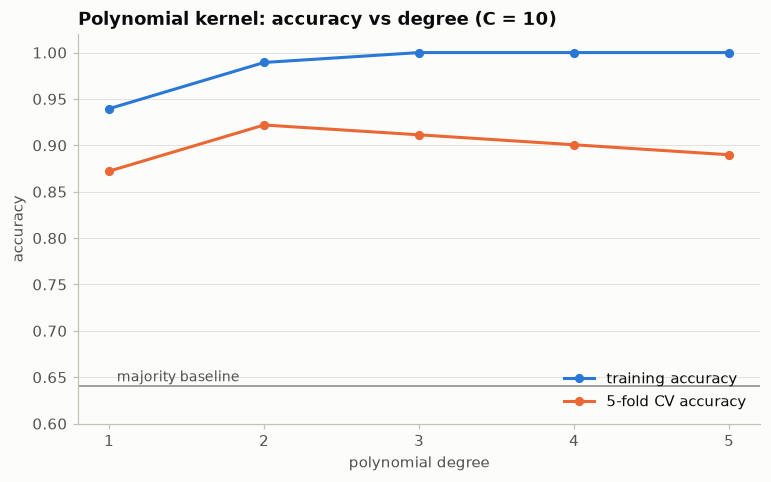

degree with the lowest CV error: 2 (C = 10, CV accuracy 0.9219)


,CV accuracy,train accuracy,support vectors
1,0.8722,0.9395,85
2,0.9219,0.9893,69
3,0.9113,1.0000,61
4,0.9006,1.0000,62
5,0.8898,1.0000,67


In [24]:
start = time.time()
poly_kernels = {d: poly_kernel(d, GAMMA_POLY_FULL, COEF0) for d in DEGREES}
poly_grid = cv_grid(X_train, y_train, poly_kernels)
best_degree, C_poly = best_setting(poly_grid)
poly_curve = fixed_C_curve(X_train, y_train, poly_kernels, poly_grid, C_poly)
print(f"all {len(RETAINED)} features ({time.time() - start:.0f}s). CV accuracy for every (degree, C):")
display(poly_grid.rename_axis("degree").style.format("{:.4f}").highlight_max(axis=None, props="font-weight: bold"))

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(DEGREES, poly_curve["train accuracy"], marker="o", markersize=5, color=SERIES[0], label="training accuracy")
ax.plot(DEGREES, poly_curve["CV accuracy"], marker="o", markersize=5, color=SERIES[1], label="5-fold CV accuracy")
ax.axhline(majority_cv, color=MUTED, linewidth=1)
ax.text(1.05, majority_cv + 0.005, "majority baseline", color=INK2, fontsize=9)
ax.set(xlabel="polynomial degree", ylabel="accuracy", xticks=DEGREES, ylim=(0.6, 1.02),
       title=f"Polynomial kernel: accuracy vs degree (C = {C_poly:g})")
ax.grid(axis="x", visible=False)
ax.legend(loc="lower right")
fig.savefig(FIG / "poly_accuracy_vs_degree.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"degree with the lowest CV error: {best_degree} (C = {C_poly:g}, CV accuracy {poly_grid.loc[best_degree, C_poly]:.4f})")
poly_curve.style.format({"CV accuracy": "{:.4f}", "train accuracy": "{:.4f}", "support vectors": "{:.0f}"})

**Values used:** γ = 1/33 ≈ 0.0303 on all 33 retained features, γ = 1/2 on the two-feature pair, coef0 = 1 throughout.

**Degree with the lowest CV error: 2** (C = 10, CV accuracy **0.9219**). At C = 10:

| Degree | 1 | **2** | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Training accuracy | 0.940 | 0.989 | 1.000 | 1.000 | 1.000 |
| CV accuracy | 0.872 | **0.922** | 0.911 | 0.901 | 0.890 |

- **Below degree 2 (degree 1): underfitting.** The kernel is effectively linear, so training accuracy is only 0.94 and CV accuracy 0.87.
- **Above degree 2 (degrees 3–5): overfitting.** Training accuracy reaches 100%, but CV accuracy falls steadily (0.911, 0.901, 0.890). The extra flexibility fits details of the training folds that do not generalize.

**What the boundary looks like on the a21 & a28 pair** (C = 10 in all panels):
- **Degree 1 (below the best degree):** no boundary inside the data range. Like the linear SVM, it labels everything "good" (CV accuracy 0.619, all 281 points are support vectors).
- **Degree 2 (the best degree on all features):** a smooth **horizontal band**, two gently curved lines that label the extreme a28 values as "bad". It captures the outer ring but not the bad cluster in the middle (CV accuracy 0.776).
- **Degrees 3–5 (above it):** the boundary becomes more and more flexible.
  - **Degree 3:** the band bends asymmetrically.
  - **Degree 4:** it carves a **pocket** around the middle bad cluster.
  - **Degree 5:** it adds a separate "bad" island in the top-right corner and wraps tightly around individual groups of points.

On this 2-D pair, the extra flexibility is still useful (CV accuracy rises to 0.879 at degree 5, the best on the pair), because two features alone need a complicated boundary. On all 33 features a quadratic boundary is already enough, and higher degrees start to overfit.

### 2.3.3 RBF kernel

$$K(x, x') = \exp\bigl(-\gamma\,\lVert x - x'\rVert^2\bigr), \qquad \gamma \in \{10^{-3}, 10^{-2}, 10^{-1}, 1, 10, 100\}.$$

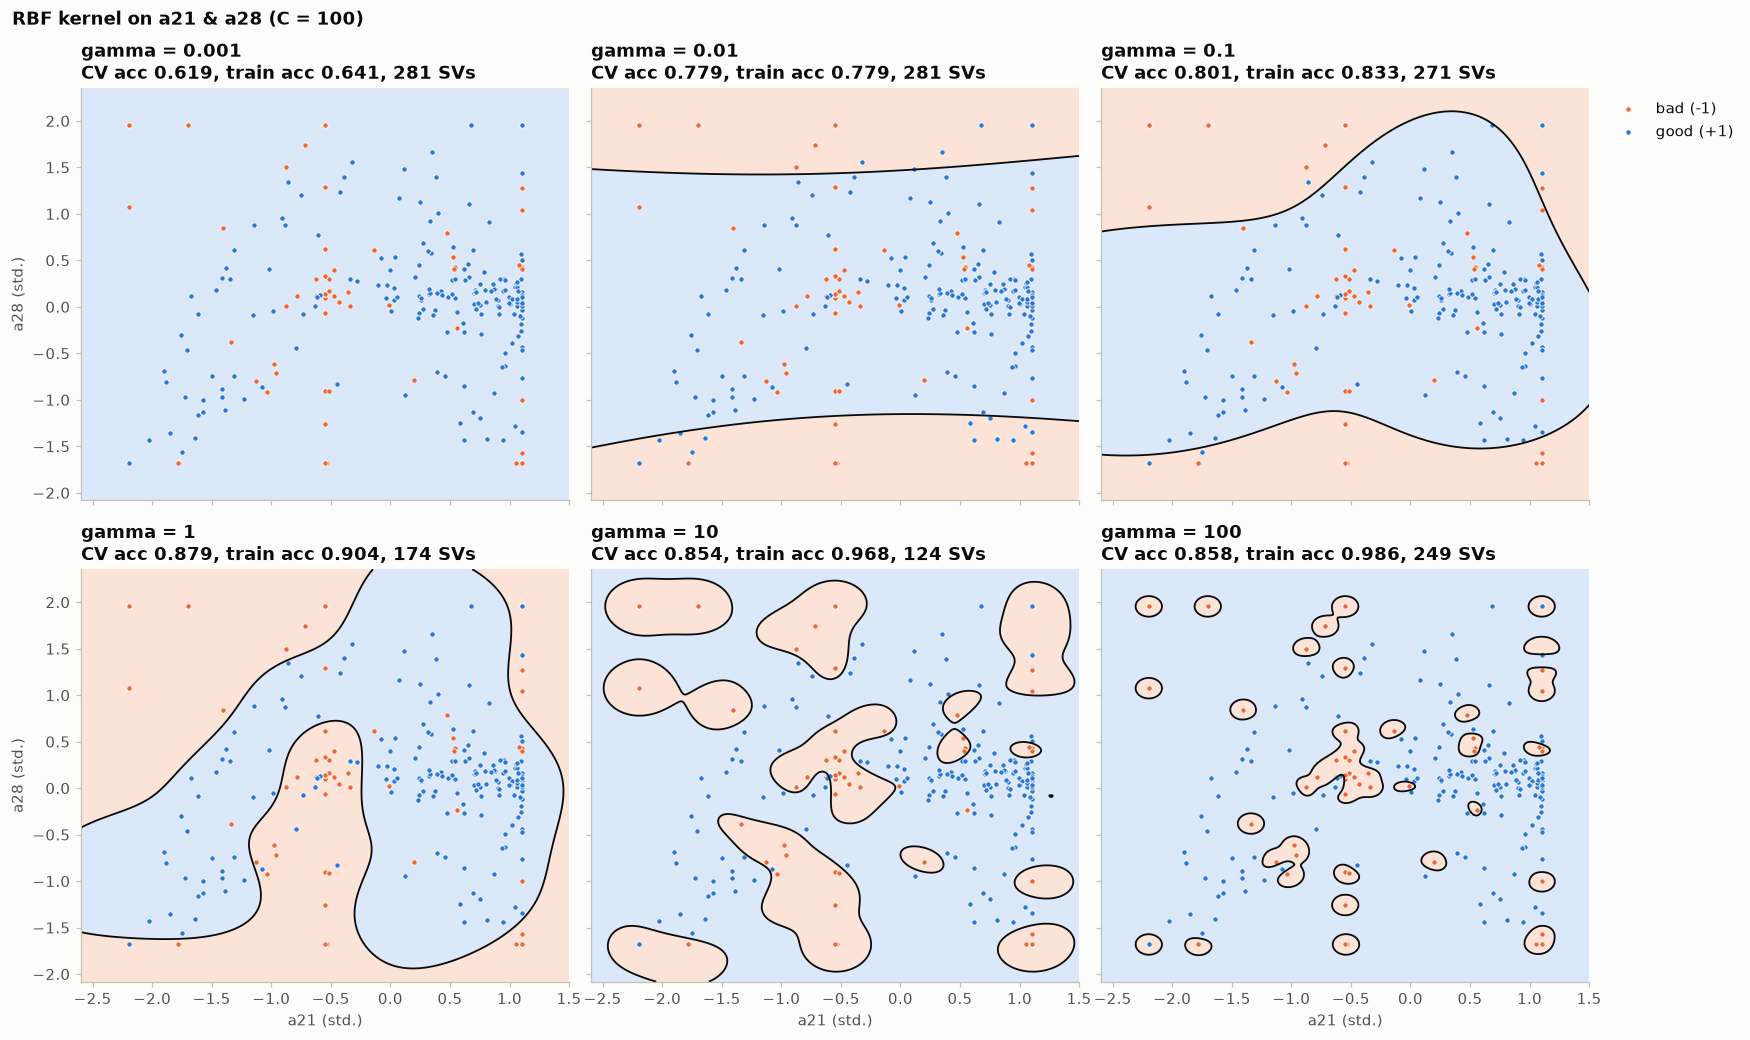

pair sweep: 8s; best on the pair: gamma 1, C = 100 (CV accuracy 0.8788); all panels use C = 100


,0.010000,0.100000,1.000000,10.000000,100.000000
gamma,,,,,
0.001000,0.6406,0.6406,0.6406,0.6406,0.6192
0.010000,0.6406,0.6406,0.6406,0.6798,0.7791
0.100000,0.6406,0.6406,0.7685,0.7720,0.8005
1.000000,0.6406,0.7721,0.8573,0.8752,0.8788
10.000000,0.6406,0.7365,0.8611,0.8363,0.8542
100.000000,0.6406,0.6975,0.8684,0.8684,0.8577


,CV accuracy,train accuracy,support vectors
0.001000,0.6192,0.6406,281
0.010000,0.7791,0.7794,281
0.100000,0.8005,0.8327,271
1.000000,0.8788,0.9039,174
10.000000,0.8542,0.9680,124
100.000000,0.8577,0.9858,249


In [25]:
GAMMAS = [1e-3, 1e-2, 1e-1, 1, 10, 100]
start = time.time()
rbf_kernels_pair = {g: rbf_kernel(g) for g in GAMMAS}
rbf_pair_grid = cv_grid(X_pair, y_train, rbf_kernels_pair)
g_pair, C_rbf_pair = best_setting(rbf_pair_grid)
rbf_pair_curve = fixed_C_curve(X_pair, y_train, rbf_kernels_pair, rbf_pair_grid, C_rbf_pair)

fig, axes = plt.subplots(2, 3, figsize=(16, 9.6), sharex=True, sharey=True)
for ax, g in zip(axes.ravel(), GAMMAS):
    plot_boundary(ax, fit_dual_svm(X_pair, y_train, C_rbf_pair, rbf_kernels_pair[g]), X_pair, y_train,
                  f"gamma = {g:g}\nCV acc {rbf_pair_curve.loc[g, 'CV accuracy']:.3f}, "
                  f"train acc {rbf_pair_curve.loc[g, 'train accuracy']:.3f}, {rbf_pair_curve.loc[g, 'support vectors']:.0f} SVs")
for ax in axes[1]:
    ax.set(xlabel=f"{PAIR_23[0]} (std.)")
for ax in axes[:, 0]:
    ax.set(ylabel=f"{PAIR_23[1]} (std.)")
axes[0, -1].legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
fig.suptitle(f"RBF kernel on {PAIR_23[0]} & {PAIR_23[1]} (C = {C_rbf_pair:g})", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "rbf_pair_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"pair sweep: {time.time() - start:.0f}s; best on the pair: gamma {g_pair:g}, C = {C_rbf_pair:g} "
      f"(CV accuracy {rbf_pair_grid.loc[g_pair, C_rbf_pair]:.4f}); all panels use C = {C_rbf_pair:g}")
display(rbf_pair_grid.rename_axis("gamma").style.format("{:.4f}").highlight_max(axis=None, props="font-weight: bold"))
rbf_pair_curve.style.format({"CV accuracy": "{:.4f}", "train accuracy": "{:.4f}", "support vectors": "{:.0f}"})

all 33 features (3s). CV accuracy for every (gamma, C):


,0.010000,0.100000,1.000000,10.000000,100.000000
gamma,,,,,
0.001000,0.6406,0.6406,0.7615,0.8970,0.9290
0.010000,0.6406,0.7225,0.9325,0.9575,0.9610
0.100000,0.6406,0.6727,0.9538,0.9645,0.9680
1.000000,0.6406,0.6406,0.6727,0.6727,0.6727
10.000000,0.6406,0.6406,0.6406,0.6477,0.6477
100.000000,0.6406,0.6406,0.6406,0.6406,0.6406


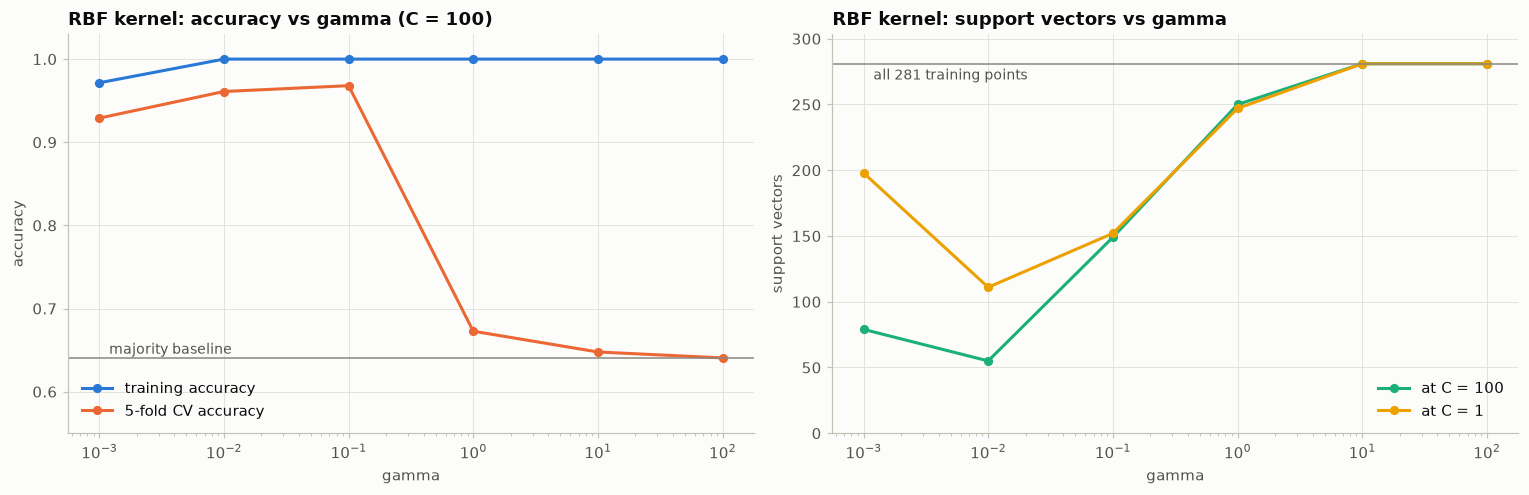

gamma with the lowest CV error: 0.1 (C = 100, CV accuracy 0.9680)
support vectors at C = 1: {0.001: 198, 0.01: 111, 0.1: 152, 1: 247, 10: 281, 100: 281}


,CV accuracy,train accuracy,support vectors
0.001000,0.9290,0.9715,79
0.010000,0.9610,1.0000,55
0.100000,0.9680,1.0000,149
1.000000,0.6727,1.0000,250
10.000000,0.6477,1.0000,281
100.000000,0.6406,1.0000,281


In [26]:
start = time.time()
rbf_kernels = {g: rbf_kernel(g) for g in GAMMAS}
rbf_grid = cv_grid(X_train, y_train, rbf_kernels)
best_gamma, C_rbf = best_setting(rbf_grid)
rbf_curve = fixed_C_curve(X_train, y_train, rbf_kernels, rbf_grid, C_rbf)
print(f"all {len(RETAINED)} features ({time.time() - start:.0f}s). CV accuracy for every (gamma, C):")
display(rbf_grid.rename_axis("gamma").style.format("{:.4f}").highlight_max(axis=None, props="font-weight: bold"))

sv_fixed_C = {g: int(fit_dual_svm(X_train, y_train, 1.0, rbf_kernels[g])["sv"].sum()) for g in GAMMAS}
fig, (ax, ax_sv) = plt.subplots(1, 2, figsize=(14, 4.6))
ax.plot(GAMMAS, rbf_curve["train accuracy"], marker="o", markersize=5, color=SERIES[0], label="training accuracy")
ax.plot(GAMMAS, rbf_curve["CV accuracy"], marker="o", markersize=5, color=SERIES[1], label="5-fold CV accuracy")
ax.axhline(majority_cv, color=MUTED, linewidth=1)
ax.text(1.2e-3, majority_cv + 0.005, "majority baseline", color=INK2, fontsize=9)
ax.set(xscale="log", xlabel="gamma", ylabel="accuracy", ylim=(0.55, 1.03),
       title=f"RBF kernel: accuracy vs gamma (C = {C_rbf:g})")
ax.legend(loc="lower left")
ax_sv.plot(GAMMAS, rbf_curve["support vectors"], marker="o", markersize=5, color=SERIES[2], label=f"at C = {C_rbf:g}")
ax_sv.plot(GAMMAS, list(sv_fixed_C.values()), marker="o", markersize=5, color=SERIES[3], label="at C = 1")
ax_sv.axhline(len(y_train), color=MUTED, linewidth=1)
ax_sv.text(1.2e-3, len(y_train) - 12, f"all {len(y_train)} training points", color=INK2, fontsize=9)
ax_sv.set(xscale="log", xlabel="gamma", ylabel="support vectors", ylim=(0, len(y_train) * 1.08),
          title="RBF kernel: support vectors vs gamma")
ax_sv.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "rbf_accuracy_vs_gamma.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"gamma with the lowest CV error: {best_gamma:g} (C = {C_rbf:g}, CV accuracy {rbf_grid.loc[best_gamma, C_rbf]:.4f})")
print("support vectors at C = 1:", sv_fixed_C)
rbf_curve.style.format({"CV accuracy": "{:.4f}", "train accuracy": "{:.4f}", "support vectors": "{:.0f}"})

**Best γ: 0.1** (C = 100, CV accuracy **0.9680**). At C = 100:

| γ | 0.001 | 0.01 | **0.1** | 1 | 10 | 100 |
|---|---|---|---|---|---|---|
| Training accuracy | 0.972 | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 |
| CV accuracy | 0.929 | 0.961 | **0.968** | 0.673 | 0.648 | 0.641 |
| Support vectors | 79 | 55 | 149 | 250 | 281 | 281 |

**Small γ extreme (0.001): very smooth, almost linear boundary.** $\exp(-\gamma\lVert x - x'\rVert^2)$ barely changes over the whole data range, so every point looks similar to every other and the decision function is close to a linear one.
- **On the pair:** γ = 0.001 draws no boundary at all (everything "good", like the linear SVM), and γ = 0.01 draws two almost straight horizontal bands.
- **On all features:** the model slightly underfits (training accuracy 0.972, CV accuracy 0.929).

**Large γ extreme (10, 100): the boundary breaks into small islands.** The kernel is so local that each training point only "sees" itself.
- **On the pair:** γ = 100 draws a tiny closed curve around almost every individual bad training point, and everything else defaults to "good".
- **On all features:** the model memorizes the training set (training accuracy 1.0) but CV accuracy collapses to the majority baseline (0.648 at γ = 10, 0.641 at γ = 100), because a new point is far from every training point and gets roughly the default label.

**Support vectors at the extremes.**
- **Large γ:** the number of support vectors rises to **all 281 training points** at γ = 10 and 100. The kernel matrix is close to the identity, so no point can be explained by its neighbours and every point must support its own label.
- **Small γ:** the count depends on C: 79 at C = 100, but **198 at C = 1**. The near-linear boundary cannot separate the classes well, so many points sit inside the margin at the bound α = C.
- **In between:** the count is lowest at intermediate γ (55 at γ = 0.01 and C = 100).

### 2.3.4 Comparative study

Each kernel at its CV-selected settings: linear at C = 0.1 (2.2), polynomial at the best degree and its C, RBF at the best γ and its C. Training time is for a single fit on the full training set (best of 5 runs).

In [27]:
kernel_configs = {
    "linear": {"setting": "-", "kernel": linear_kernel, "C": C_LINEAR,
               "CV accuracy": cv_dual_linear},
    "polynomial": {"setting": f"degree {best_degree}, gamma 1/33, coef0 1", "kernel": poly_kernels[best_degree],
                   "C": C_poly, "CV accuracy": poly_grid.loc[best_degree, C_poly]},
    "RBF": {"setting": f"gamma {best_gamma:g}", "kernel": rbf_kernels[best_gamma],
            "C": C_rbf, "CV accuracy": rbf_grid.loc[best_gamma, C_rbf]},
}
rows = {}
for name, cfg in kernel_configs.items():
    model = fit_dual_svm(X_train, y_train, cfg["C"], cfg["kernel"])
    rows[name] = {"setting": cfg["setting"], "C": cfg["C"], "CV accuracy": cfg["CV accuracy"],
                  "support vectors": int(model["sv"].sum()),
                  "training time (s)": best_time(lambda cfg=cfg: fit_dual_svm(X_train, y_train, cfg["C"], cfg["kernel"]))}
kernel_table = pd.DataFrame(rows).T
CHOSEN_KERNEL = kernel_table["CV accuracy"].astype(float).idxmax()
print(f"chosen kernel (highest CV accuracy): {CHOSEN_KERNEL}")
kernel_table.style.format({"C": "{:g}", "CV accuracy": "{:.4f}", "support vectors": "{:.0f}", "training time (s)": "{:.3f}"})

chosen kernel (highest CV accuracy): RBF


,setting,C,CV accuracy,support vectors,training time (s)
linear,-,0.1,0.8792,96,0.056
polynomial,"degree 2, gamma 1/33, coef0 1",10,0.9219,69,0.056
RBF,gamma 0.1,100,0.9680,149,0.043


| Kernel | Setting | C | CV accuracy | Support vectors | Training time (one fit) |
|---|---|---|---|---|---|
| Linear | – | 0.1 | 0.8792 | 96 | ≈ 0.05 s |
| Polynomial | degree 2, γ = 1/33, coef0 = 1 | 10 | 0.9219 | 69 | ≈ 0.07 s |
| **RBF** | **γ = 0.1** | **100** | **0.9680** | 149 | ≈ 0.07 s |

Training times are all similar and vary a little between runs. With 281 training rows the cost is dominated by the same 281 × 281 QP, whichever kernel fills the matrix.

**I would choose the RBF kernel.** It has the highest CV accuracy by a clear margin: 4.6 points above the polynomial kernel and 8.9 above linear.

**Why it wins on Ionosphere.** A "good" return is a real reflection from structure in the ionosphere, so its 17 pulse measurements follow a consistent, repeatable pattern. That is visible in 2.1.4: good returns form one tight cluster in the a03/a05 plot, and the odd-numbered features are strongly correlated. A "bad" return passes straight through, so its values are close to noise and are scattered in every direction around that cluster, including many saturated 0 and ±1 values.

The question the classifier has to answer is therefore "is this return close to the typical good pattern?". That describes a **closed region around a compact cluster**, not one side of a hyperplane. An RBF decision function is a weighted sum of similarities $\exp(-\gamma\lVert x - x_i\rVert^2)$ to the support vectors, so it naturally draws closed, local boundaries around such a cluster:
- **Linear kernel:** can only cut the space in half.
- **Degree-2 polynomial:** its quadratic, ellipsoid-like boundaries can enclose the cluster only roughly, which explains its second place.

## 2.4 The Regularization Parameter C

The kernel chosen in 2.3.4 is kept fixed and C is swept over {0.01, 0.1, 1, 10, 100}. For each C: training error of a fit on the full training set, 5-fold CV error, and the number of support vectors of the full-training-set fit.

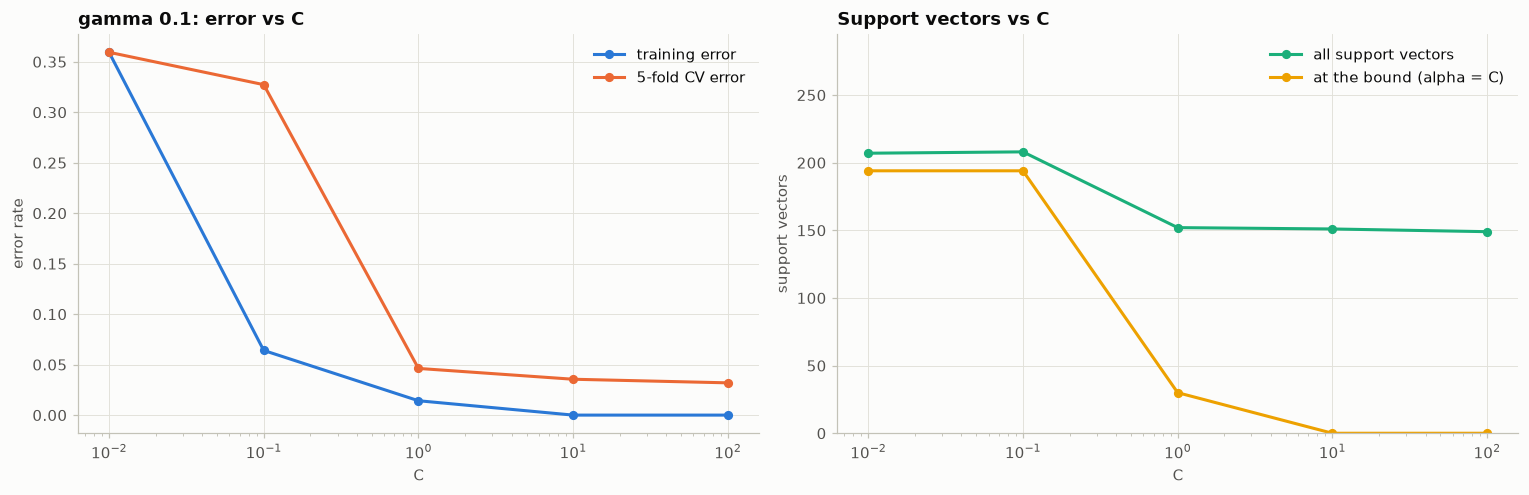

kernel: RBF (gamma 0.1)
C with the lowest CV error (smallest among ties): 100, CV error 0.0320
improvement over the smallest C (0.01, CV error 0.3594): 0.3274 (32.7 percentage points)


,training error,CV error,support vectors,SVs at bound (alpha = C)
C,,,,
0.010000,0.3594,0.3594,207,194
0.100000,0.0641,0.3273,208,194
1.000000,0.0142,0.0462,152,30
10.000000,0.0000,0.0355,151,0
100.000000,0.0000,0.0320,149,0


In [28]:
C_SWEEP = [1e-2, 1e-1, 1, 10, 100]
chosen_k = kernel_configs[CHOSEN_KERNEL]["kernel"]
rows = {}
for C in C_SWEEP:
    model = fit_dual_svm(X_train, y_train, C, chosen_k)
    cv_acc = cross_val_accuracy(lambda X, y, C=C: fit_dual_svm(X, y, C, chosen_k), dual_predict, X_train, y_train, folds)[0]
    rows[C] = {"training error": 1 - accuracy(y_train, dual_predict(model, X_train)), "CV error": 1 - cv_acc,
               "support vectors": int(model["sv"].sum()), "SVs at bound (alpha = C)": int((model["sv"] & ~model["on_margin"]).sum())}
c_sweep = pd.DataFrame(rows).T.rename_axis("C")
best_C_24 = c_sweep["CV error"].idxmin()   # first (smallest) C among ties

fig, (ax, ax_sv) = plt.subplots(1, 2, figsize=(14, 4.6))
ax.plot(C_SWEEP, c_sweep["training error"], marker="o", markersize=5, color=SERIES[0], label="training error")
ax.plot(C_SWEEP, c_sweep["CV error"], marker="o", markersize=5, color=SERIES[1], label="5-fold CV error")
ax.set(xscale="log", xlabel="C", ylabel="error rate", title=f"{kernel_configs[CHOSEN_KERNEL]['setting']}: error vs C")
ax.legend(loc="upper right")
ax_sv.plot(C_SWEEP, c_sweep["support vectors"], marker="o", markersize=5, color=SERIES[2], label="all support vectors")
ax_sv.plot(C_SWEEP, c_sweep["SVs at bound (alpha = C)"], marker="o", markersize=5, color=SERIES[3], label="at the bound (alpha = C)")
ax_sv.set(xscale="log", xlabel="C", ylabel="support vectors", ylim=(0, len(y_train) * 1.05),
          title="Support vectors vs C")
ax_sv.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "c_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

base = c_sweep.loc[C_SWEEP[0], "CV error"]
print(f"kernel: {CHOSEN_KERNEL} ({kernel_configs[CHOSEN_KERNEL]['setting']})")
print(f"C with the lowest CV error (smallest among ties): {best_C_24:g}, CV error {c_sweep.loc[best_C_24, 'CV error']:.4f}")
print(f"improvement over the smallest C ({C_SWEEP[0]:g}, CV error {base:.4f}): {base - c_sweep.loc[best_C_24, 'CV error']:.4f} "
      f"({100 * (base - c_sweep.loc[best_C_24, 'CV error']):.1f} percentage points)")
c_sweep.style.format({"training error": "{:.4f}", "CV error": "{:.4f}", "support vectors": "{:.0f}", "SVs at bound (alpha = C)": "{:.0f}"})

**Kernel: RBF, γ = 0.1.**

| C | 0.01 | 0.1 | 1 | 10 | **100** |
|---|---|---|---|---|---|
| Training error | 0.359 | 0.064 | 0.014 | 0.000 | 0.000 |
| CV error | 0.359 | 0.327 | 0.046 | 0.036 | **0.032** |
| Support vectors | 207 | 208 | 152 | 151 | 149 |
| … at the bound (α = C) | 194 | 194 | 30 | 0 | 0 |

**Best C: 100** (CV error **0.0320**, no tie). Compared with the smallest C (0.01, CV error 0.3594), that is an improvement of **0.327, i.e. 32.7 percentage points** of CV error. Most of the gain comes from 0.1 to 1. From C = 1 onwards the CV error only drifts down by about 1.4 points (roughly 4 validation points over the five folds). C = 100 is at the edge of the sweep, but the curve has flattened there.

**What C controls.** C is the price paid for each unit of margin violation (the hinge loss) relative to having a wide margin, and it is also the upper limit on every α.
- **Small C:** violations are cheap and every α is capped at a tiny value, so the decision function $\sum_i \alpha_i y_i K(x_i, x) + b$ is almost constant. At C = 0.01 the model predicts "good" everywhere: training and CV error both equal the majority-class error of 0.359. This is heavy underfitting. At C = 0.1 the model starts to bend on the training set (training error 0.064) but still behaves almost like the baseline on held-out folds (CV error 0.327).
- **Large C:** violations become expensive, so the model fits the training data more tightly. Training error drops to 0 from C = 10, and CV error drops with it to about 0.03. With γ = 0.1 the boundary is smooth enough that fitting the training set exactly does not yet hurt CV error within this sweep, so there is no overfitting upturn up to C = 100.

**Support vectors as C grows.** The number of support vectors **falls** from about 207 to 149. With small C the margin is wide and almost every point lies inside it, pinned at the bound α = C (194 of 207). As C increases the margin narrows, fewer points violate it, and the bound support vectors disappear entirely (0 from C = 10). The remaining ~150 are margin support vectors that define the boundary in 33 dimensions. The count levels off rather than going to zero, because a curved boundary in 33 dimensions needs many points to pin it down.

## 2.5 Evaluation

**C is tuned separately for each SVM** by 5-fold CV on the training set, with the kernel settings chosen in 2.2–2.3 held fixed (linear; polynomial degree 2 with γ = 1/33 and coef0 = 1; RBF with γ = 0.1). Ties go to the smallest C. Each model is then refit on the full training set and evaluated **once** on the 70-row test set, which has not been used anywhere before this point. The trivial baseline always predicts the majority class of the training set.

In [29]:
tuning = pd.DataFrame({
    "linear SVM": dual_cv_by_C.iloc[0],
    f"polynomial SVM (degree {best_degree})": poly_grid.loc[best_degree],
    f"RBF SVM (gamma {best_gamma:g})": rbf_grid.loc[best_gamma],
}).T
tuning.columns = [f"C = {C:g}" for C in C_GRID]
tuned_C = {name: C_GRID[int(np.argmax(row.to_numpy()))] for name, row in tuning.iterrows()}
tuning["selected C"] = [tuned_C[name] for name in tuning.index]
print("5-fold CV accuracy by C (selected C = highest CV accuracy, smallest on ties):")
tuning.style.format({c: "{:.4f}" for c in tuning.columns if c != "selected C"} | {"selected C": "{:g}"})

5-fold CV accuracy by C (selected C = highest CV accuracy, smallest on ties):


,C = 0.01,C = 0.1,C = 1,C = 10,C = 100,selected C
linear SVM,0.8722,0.8792,0.8722,0.8509,0.8439,0.1
polynomial SVM (degree 2),0.6406,0.8722,0.9005,0.9219,0.9079,10
RBF SVM (gamma 0.1),0.6406,0.6727,0.9538,0.9645,0.9680,100


In [30]:
final_kernels = {
    "linear SVM": linear_kernel,
    f"polynomial SVM (degree {best_degree})": poly_kernels[best_degree],
    f"RBF SVM (gamma {best_gamma:g})": rbf_kernels[best_gamma],
}
final_models = {name: fit_dual_svm(X_train, y_train, tuned_C[name], k) for name, k in final_kernels.items()}
test_predictions = {name: dual_predict(m, X_test) for name, m in final_models.items()}
majority_label = fit_majority(X_train, y_train)
test_predictions["trivial (always majority)"] = predict_majority(majority_label, X_test)

rows, cms = {}, {}
for name, pred in test_predictions.items():
    (tp, fn), (fp, tn) = confusion_matrix(y_test, pred)
    rows[name] = {"C": tuned_C.get(name, np.nan), "accuracy": accuracy(y_test, pred), "precision": precision(y_test, pred),
                  "recall": recall(y_test, pred), "F1": f1(y_test, pred), "TP": tp, "FN": fn, "FP": fp, "TN": tn}
test_results = pd.DataFrame(rows).T
print(f"test set: {len(y_test)} rows ({int(np.sum(y_test == 1))} good, {int(np.sum(y_test == -1))} bad); "
      f"majority class of the training set = {CLASS_NAME[majority_label]}")
print("precision, recall and F1 are for the positive class (good); TP/FN/FP/TN from the confusion matrix")
test_results.style.format({"C": "{:g}", "accuracy": "{:.4f}", "precision": "{:.4f}", "recall": "{:.4f}", "F1": "{:.4f}",
                           "TP": "{:.0f}", "FN": "{:.0f}", "FP": "{:.0f}", "TN": "{:.0f}"}, na_rep="-")

test set: 70 rows (45 good, 25 bad); majority class of the training set = good (+1)
precision, recall and F1 are for the positive class (good); TP/FN/FP/TN from the confusion matrix


,C,accuracy,precision,recall,F1,TP,FN,FP,TN
linear SVM,0.1,0.8857,0.8776,0.9556,0.9149,43,2,6,19
polynomial SVM (degree 2),10,0.9000,0.9130,0.9333,0.9231,42,3,4,21
RBF SVM (gamma 0.1),100,0.9286,0.9762,0.9111,0.9425,41,4,1,24
trivial (always majority),-,0.6429,0.6429,1.0000,0.7826,45,0,25,0


**C used for each SVM** (tuned by 5-fold CV): linear **C = 0.1**, polynomial (degree 2) **C = 10**, RBF (γ = 0.1) **C = 100**.

**Test-set results** (positive class = good; 70 test rows: 45 good, 25 bad):

| Model | C | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|
| Linear SVM | 0.1 | 0.8857 | 0.8776 | 0.9556 | 0.9149 |
| Polynomial SVM (degree 2) | 10 | 0.9000 | 0.9130 | 0.9333 | 0.9231 |
| **RBF SVM (γ = 0.1)** | 100 | **0.9286** | **0.9762** | 0.9111 | **0.9425** |
| Trivial (always "good") | – | 0.6429 | 0.6429 | 1.0000 | 0.7826 |

- **RBF is best** on accuracy, precision and F1. It calls only **1** of the 25 bad returns "good" (precision 0.976), while the linear SVM lets **6** bad returns through. That is the "bad returns that look good" pattern analysed in 2.6. The RBF model pays with slightly lower recall (4 good returns missed, against 2 for linear).
- **The test ranking matches the CV ranking:** RBF > polynomial > linear > trivial.
- **Test accuracy is a little below CV accuracy for RBF (0.929 vs 0.968).** That is expected noise with 70 test rows: one row is 1.4 percentage points, and the standard error of an accuracy near 0.93 on 70 rows is about 3 points.

**What the trivial baseline's accuracy conceals.** It scores **64.3%** accuracy, recall **1.0** and F1 **0.78**, which look respectable. That is only because "good" is both the majority class (64% of the data, see 2.1.2) and the positive class. The confusion matrix shows the truth: **TN = 0, FP = 25**. It never identifies a single bad return and uses no information from the radar signal at all. With a 64 : 36 class balance, accuracy has to be judged against 64%, not 50%, and a model is only useful to the extent that it finds the minority "bad" class. That needs the confusion matrix or per-class precision and recall, not accuracy (or positive-class recall) alone.

## 2.6 Support Vectors and Error Analysis

The **best overall model** is the RBF SVM (γ = 0.1, C = 100): it has the highest CV accuracy (0.968), which is how it was selected; its test result above agrees. The **linear SVM from 2.2.2** is the dual/QP linear SVM at C = 0.1. Hinge loss of training point $i$ is $\max(0,\, 1 - y_i f(x_i))$; a point counts as having non-zero hinge loss if this exceeds 1e-3.

In [31]:
best_name = f"RBF SVM (gamma {best_gamma:g})"
best_model = final_models[best_name]
n_sv_best = int(best_model["sv"].sum())
print(f"best overall model: {best_name}, C = {tuned_C[best_name]:g}")
print(f"support vectors: {n_sv_best} of {len(y_train)} = {n_sv_best / len(y_train):.1%} of the training set "
      f"({int(best_model['on_margin'].sum())} on the margin, {n_sv_best - int(best_model['on_margin'].sum())} at the bound alpha = C)")

hinge_rows = {}
for name, model in [(best_name + f", C = {tuned_C[best_name]:g}", best_model), (f"linear SVM (2.2.2), C = {C_LINEAR:g}", dual_linear)]:
    f_train = dual_decision(model, X_train)
    hinge = np.maximum(0.0, 1 - y_train * f_train)
    hinge_rows[name] = {"support vectors": int(model["sv"].sum()), "hinge loss > 1e-3": int(np.sum(hinge > 1e-3)),
                        "inside the margin but correct (0 < hinge <= 1)": int(np.sum((hinge > 1e-3) & (hinge <= 1))),
                        "misclassified (hinge > 1)": int(np.sum(hinge > 1)), "largest hinge loss": hinge.max(),
                        "total hinge loss": hinge.sum()}
pd.DataFrame(hinge_rows).T.style.format({"largest hinge loss": "{:.3g}", "total hinge loss": "{:.3g}"}, precision=0)

best overall model: RBF SVM (gamma 0.1), C = 100
support vectors: 149 of 281 = 53.0% of the training set (149 on the margin, 0 at the bound alpha = C)


,support vectors,hinge loss > 1e-3,inside the margin but correct (0 < hinge <= 1),misclassified (hinge > 1),largest hinge loss,total hinge loss
"RBF SVM (gamma 0.1), C = 100",149,0,0,0,0.000113,0.00603
"linear SVM (2.2.2), C = 0.1",96,76,52,24,3.37,60.2


**Support vectors of the best model (support vectors: α > 1e-5):** 149 of 281 training points, **53.0% of the training set**. All 149 lie exactly on the margin (0 < α < C) and none are at the bound.

**What that fraction suggests about the fit:**
- **The fit is flexible and local.** More than half of the training points are needed to define the boundary. With γ = 0.1 each support vector only influences its own neighbourhood, so the boundary is built piece by piece from many points rather than from a few that pin down a simple surface.
- **Nothing is left inside the margin.** With C = 100 and no support vectors at the bound, every training point is on or outside its margin. The training set is separated perfectly, which on its own would be a warning sign of overfitting. The standard leave-one-out bound (error ≤ #SV / n = 0.53) is too loose to reassure, but the CV accuracy (0.968) and test accuracy (0.929) show the fit still generalizes here.
- **For comparison, the linear SVM** uses fewer support vectors (96, 34%), but 76 of them are margin violators. It is simpler but cannot separate the classes.

**Training points with non-zero hinge loss (hinge > 1e-3):**
- **RBF (best model): 0.** The largest hinge loss is 1.1e-4 and the total is 0.006.
- **Linear SVM from 2.2.2: 76.** 52 are correctly classified but inside the margin, and 24 are misclassified. The total hinge loss is 60.2.

**Why they differ:** the RBF kernel with a large C can bend the boundary around every training point, so it pays essentially no hinge loss. The linear SVM is limited to a hyperplane and is also strongly regularized (C = 0.1), so it accepts 76 violations as the price of a wide margin. Zero training hinge loss is not a virtue in itself, since it is also what memorization looks like; here the CV and test results confirm the RBF fit is genuinely better rather than just more flexible.

In [32]:
f_lin = dual_decision(dual_linear, X_train)
hinge_lin = np.maximum(0.0, 1 - y_train * f_lin)
good_centre = X_train[y_train == 1].mean(axis=0)
PULSES = [(f"a{k:02d}", f"a{k + 1:02d}") for k in range(3, 34, 2)]
magnitude = np.column_stack([np.hypot(X_train_raw[:, RETAINED.index(a)], X_train_raw[:, RETAINED.index(b)]) for a, b in PULSES])

inspect = pd.DataFrame({
    "label": [CLASS_NAME[c] for c in y_train],
    "f(x) linear": f_lin,
    "hinge loss": hinge_lin,
    "y*f(x) RBF": y_train * dual_decision(best_model, X_train),
    "a01": X_train_raw[:, RETAINED.index("a01")],
    "a03": X_train_raw[:, RETAINED.index("a03")],
    "a05": X_train_raw[:, RETAINED.index("a05")],
    "distance to good centre": np.linalg.norm(X_train - good_centre, axis=1),
    "mean pulse magnitude": magnitude.mean(axis=1),
    "pulse magnitude spread (std)": magnitude.std(axis=1),
    "values exactly 0 or +-1": ((X_train_raw == 0) | (np.abs(X_train_raw) == 1)).sum(axis=1),
}, index=pd.Index(train_idx, name="row in dataset"))
worst = inspect.sort_values("hinge loss", ascending=False)
TOP = 15
print(f"class of the {TOP} largest-hinge-loss training points:", worst.head(TOP)["label"].value_counts().to_dict())
print(f"class of the 20 largest:", worst.head(20)["label"].value_counts().to_dict())
worst.head(10).style.format(precision=3)

class of the 15 largest-hinge-loss training points: {'bad (-1)': 15}
class of the 20 largest: {'bad (-1)': 17, 'good (+1)': 3}


,label,f(x) linear,hinge loss,y*f(x) RBF,a01,a03,a05,distance to good centre,mean pulse magnitude,pulse magnitude spread (std),values exactly 0 or +-1
row in dataset,,,,,,,,,,,
126,bad (-1),2.366,3.366,1.000,1.000,0.598,0.828,5.361,1.003,0.228,2
87,bad (-1),1.693,2.693,1.000,1.000,0.727,0.892,4.392,0.830,0.314,7
85,bad (-1),1.545,2.545,1.000,1.000,0.392,0.975,3.550,0.659,0.299,3
148,bad (-1),1.175,2.175,1.000,1.000,0.853,1.000,5.504,1.085,0.237,14
116,bad (-1),1.142,2.142,1.000,1.000,1.000,1.000,2.279,0.659,0.225,5
83,bad (-1),0.840,1.840,1.000,1.000,0.682,0.823,3.672,0.413,0.273,2
244,bad (-1),0.800,1.800,1.000,1.000,0.000,1.000,4.697,0.728,0.506,21
132,bad (-1),0.776,1.776,1.000,1.000,1.000,1.000,7.149,0.860,0.672,32
142,bad (-1),0.477,1.477,1.000,1.000,1.000,1.000,5.148,0.924,0.352,15


In [33]:
top_rows = worst.head(TOP)
groups = {
    f"top {TOP} by hinge loss (linear)": top_rows,
    "other bad returns": inspect[(inspect["label"] == CLASS_NAME[-1.0]) & ~inspect.index.isin(top_rows.index)],
    "good returns": inspect[(inspect["label"] == CLASS_NAME[1.0]) & ~inspect.index.isin(top_rows.index)],
}
cols = ["a01", "a03", "a05", "distance to good centre", "mean pulse magnitude", "pulse magnitude spread (std)", "values exactly 0 or +-1"]
pd.DataFrame({name: {"rows": len(g), **{c: g[c].median() for c in cols}} for name, g in groups.items()}).T.style.format(precision=3)

,rows,a01,a03,a05,distance to good centre,mean pulse magnitude,pulse magnitude spread (std),values exactly 0 or +-1
top 15 by hinge loss (linear),15.000,1.000,0.853,0.997,4.697,0.842,0.274,7.000
other bad returns,86.000,1.000,0.137,0.000,7.548,0.744,0.419,23.000
good returns,180.000,1.000,0.905,0.868,3.491,0.843,0.092,2.000


**Is there a pattern among the largest-hinge-loss points of the linear SVM? Yes.**
- **All 15 of the largest are bad returns** (17 of the top 20), and every one of them gets a positive score f(x) from the linear model. These are not borderline cases: they are bad returns that the linear SVM **confidently calls good**, with scores up to +2.4 and hinge losses up to 3.4.
- **On the features the linear model relies on, they look like good returns.** Compared by medians in the table above:
  - They have `a01` = 1 and strong first pulses (a03 ≈ 0.85, a05 ≈ 1.00), like good returns (0.91, 0.87) and unlike other bad returns (0.14, 0.00).
  - They sit close to the good-class centre: distance 4.7, against 3.5 for good returns and 7.5 for other bad returns.
  - Their average pulse magnitude $\sqrt{a_{2k+1}^2 + a_{2k+2}^2}$ is 0.84, identical to good returns, while other bad returns have 0.74.
- **Where they differ is consistency across the 16 pulses.** The spread (standard deviation) of their pulse magnitudes is **0.27, three times that of good returns (0.09)**. They are strong but irregular signals. Several also contain many saturated values exactly at 0 or ±1 (median 7, against 2 for good returns).
- **The RBF model classifies every one of them correctly** (y·f(x) = 1.0, exactly on its margin). The information that separates them exists, but a single hyperplane over the raw real/imaginary parts cannot use it.

**Proposed change (not implemented): add pulse-magnitude features to the input of the linear SVM.**

For each of the 16 pulses, compute the magnitude $\lvert z_k\rvert = \sqrt{a_{2k+1}^2 + a_{2k+2}^2}$ of the complex autocorrelation value (the pairs a03/a04, …, a33/a34). Add those, plus one summary feature, the **spread of the magnitudes across pulses**, to the 33 existing columns, standardized with training statistics as before.

A linear model cannot compute a square root of squares or a standard deviation across columns by itself, but it can put a weight on them once they are given as features.

**What I would expect if I made it:**
- **The look-alike bad returns would get a strongly negative contribution** from the magnitude-spread feature, which separates them from good returns (0.27 vs 0.09). Many of the 15 largest hinge losses should drop, and the linear model should let fewer bad returns through on the test set (currently 6 false positives).
- **Linear CV accuracy should rise from 0.879 towards the kernel models (0.92–0.97)**, while the model stays linear, fast and interpretable (its weights would say directly that irregular pulse magnitudes mean "bad").
- **It would not fully match RBF**, because some of these points are inside the good cluster on almost every feature. It should close a large part of the gap, though.